# Monitorización de una máquina CNC industrial

## Análisis exploratorio de variables operativas y mediciones de sensores

### 1. Introducción

Este proyecto se centra en el análisis exploratorio de datos de una máquina CNC industrial.

El objetivo es comprender el comportamiento operativo y térmico de la máquina mediante la combinación de dos fuentes de datos: las variables operativas del CNC y las mediciones de diferentes sensores.

### 2. Descripción de los conjuntos de datos

El análisis utiliza dos conjuntos de datos en formato Excel:

- **CNCVariables:** variables operativas de la máquina, incluyendo cargas de los ejes, velocidades, posiciones, potencia, intensidad y temperaturas.

### SensorData

Conjunto de datos compuesto por 65 columnas y 89.393 registros, procedentes de sensores externos instalados en la máquina CNC.

Incluye dos grupos de mediciones:

- **Sensores IDS (Bar_01 a Bar_14):** 14 canales que miden deformaciones estructurales inducidas térmicamente, expresadas en micrómetros (µm).
- **Termopares (Thermocouple_01 a Thermocouple_49):** 49 canales que registran temperaturas en diferentes componentes y zonas de la máquina, expresadas en grados Celsius (°C).

La adquisición se realizó entre el 6 y el 8 de noviembre de 2024, con una frecuencia nominal de 1 Hz y periodos no continuos de registro.


En conjunto, ambos archivos contienen 179.048 registros y 106 columnas.

### 3. Objetivo del análisis

Comprender el comportamiento operativo y térmico de la máquina CNC, identificar patrones estadísticos y explorar posibles relaciones entre las condiciones de funcionamiento de la máquina y las mediciones de los sensores.

### 4. Preguntas de investigación

- **PI01:** ¿Cómo se comporta la máquina CNC durante el periodo de observación?
- **PI02:** ¿Qué diferencias existen entre las mediciones de temperatura de los distintos termopares?
- **PI03:** ¿Existe una relación entre las cargas de los ejes y las variaciones de temperatura?
- **PI04:** ¿Está relacionada la velocidad del husillo con el comportamiento térmico de la máquina?
- **PI05:** ¿Se pueden identificar patrones de calentamiento y enfriamiento?
- **PI06:** ¿Es posible identificar condiciones de funcionamiento estadísticamente inusuales?

### 5. Metodología

1. Comprensión de los datos.
2. Evaluación y limpieza de los datos.
3. Análisis univariante.
4. Análisis bivariante y multivariante.
5. Ingeniería de características (*Feature Engineering*).
6. Análisis de series temporales.
7. Exploración de anomalías.
8. Conclusiones.

### 6. Limitaciones

- No se dispone de etiquetas confirmadas de fallos o averías.
- No está documentada la ubicación física de los sensores.
- El significado de los canales Bar y sus unidades de medida requieren verificación.
- La correlación entre variables no implica causalidad.
- El modelado predictivo queda fuera del alcance inicial de este análisis exploratorio.


In [19]:
# Importamos las librerías necesarias

import pandas as pd
import numpy as np

# Configuración de visualización
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)


In [20]:
# Rutas de los archivos originales
ruta_cnc = "https://zenodo.org/records/16579804/files/CNCVariables6to8November2024.xlsx?download=1"
ruta_sensores = "https://zenodo.org/records/16579804/files/SensorData6To8November2024.xlsx?download=1"

# Lectura de los archivos Excel
cnc = pd.read_excel(ruta_cnc)
sensores = pd.read_excel(ruta_sensores)

In [21]:
# Comprobamos el número de filas y columnas

print("DIMENSIONES DE LOS DATASETS")

print(f"CNCVariables: {cnc.shape}")
print(f"SensorData: {sensores.shape}")

DIMENSIONES DE LOS DATASETS
CNCVariables: (89655, 41)
SensorData: (89393, 65)


In [22]:
# Visualizamos las primeras cinco filas
display(cnc.head())
display(sensores.head())

,Date,Timestamp,AAxisIntensity,AAxisLoad,AAxisPositionActual,AAxisPower,AAxisSpeed,CAxisIntensity,CAxisLoad,CAxisPositionActual,CAxisPower,CAxisSpeed,CAxisTemperature,ControllerMode,ExecutionState,PathFeedrateActual,PathFeedrateOverride,SPActualSpeed,SPAxisIntensity,SPAxisLoad,SPAxisPower,SPAxisTemperature,SpindleOverride,XAxisIntensity,XAxisLoad,XAxisPositionActual,XAxisPower,XAxisSpeed,XAxisTemperature,YAxisIntensity,YAxisLoad,YAxisPositionActual,YAxisPower,YAxisSpeed,YAxisTemperature,ZAxisIntensity,ZAxisLoad,ZAxisPositionActual,ZAxisPower,ZAxisSpeed,ZAxisTemperature
0,2024-11-06 06:47:47.362,1730875667.362,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,0.000,24.052,100,0.000,0.000,-0.000,-0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,-0.000,0.000,19.580
1,2024-11-06 06:47:48.362,1730875668.362,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,0.000,24.052,100,0.000,0.000,-0.000,-0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,-0.000,0.000,19.580
2,2024-11-06 06:47:49.363,1730875669.363,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,-0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,0.000,24.052,100,0.000,0.000,-0.000,0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,0.000,0.000,19.558
3,2024-11-06 06:47:50.362,1730875670.362,0.004,0.000,0.000,0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,-0.000,24.064,100,0.000,0.000,-0.000,0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,0.000,0.000,19.558
4,2024-11-06 06:47:51.362,1730875671.362,0.004,0.000,0.000,-0.000,0.000,0.018,0.000,149.134,0.000,0.000,22.000,0,5,0.000,0.000,0.000,0.000,0.000,-0.000,24.026,100,0.000,0.000,-0.000,0.000,0.000,20.500,0.000,0.000,-375.084,-0.000,0.000,19.300,0.000,0.000,375.084,0.000,0.000,19.599


,Date,Timestamp,Bar_01,Bar_02,Bar_03,Bar_04,Bar_05,Bar_06,Bar_07,Bar_08,Bar_09,Bar_10,Bar_11,Bar_12,Bar_13,Bar_14,Thermocouple_01,Thermocouple_02,Thermocouple_03,Thermocouple_04,Thermocouple_05,Thermocouple_06,Thermocouple_07,Thermocouple_08,Thermocouple_09,Thermocouple_10,Thermocouple_11,Thermocouple_12,Thermocouple_13,Thermocouple_14,Thermocouple_15,Thermocouple_16,Thermocouple_17,Thermocouple_18,Thermocouple_19,Thermocouple_20,Thermocouple_21,Thermocouple_22,Thermocouple_23,Thermocouple_24,Thermocouple_25,Thermocouple_26,Thermocouple_27,Thermocouple_28,Thermocouple_29,Thermocouple_30,Thermocouple_31,Thermocouple_32,Thermocouple_33,Thermocouple_34,Thermocouple_35,Thermocouple_36,Thermocouple_37,Thermocouple_38,Thermocouple_39,Thermocouple_40,Thermocouple_41,Thermocouple_42,Thermocouple_43,Thermocouple_44,Thermocouple_45,Thermocouple_46,Thermocouple_47,Thermocouple_48,Thermocouple_49
0,2024-11-06 06:50:07,1730875807,58962.570,61182.460,60312.920,58430.210,63274.950,61873.820,58747.520,60691.690,59931.140,61356.850,58127.300,59703.950,60970.130,58614.510,18.700,17.800,16.900,17.800,17.900,19.100,18.100,16.100,18.600,17.400,16.900,17.800,17.800,18.600,17.800,16.100,18.600,17.700,16.900,18.100,17.800,19.000,18.000,16.100,18.600,17.400,16.500,17.400,17.400,18.500,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.800,14.800,16.800
1,2024-11-06 06:50:08,1730875808,58962.590,61182.440,60312.950,58430.260,63274.950,61873.890,58747.470,60691.730,59931.170,61356.800,58127.260,59704.000,60970.170,58614.540,18.700,17.800,16.900,17.800,17.900,19.200,18.100,16.100,18.600,17.400,16.800,17.800,17.800,18.600,17.800,16.100,18.600,17.700,16.900,18.100,17.800,19.000,18.100,16.100,18.600,17.400,16.600,17.400,17.400,18.600,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.700,14.800,16.800
2,2024-11-06 06:50:09,1730875809,58962.620,61182.460,60312.950,58430.260,63275.020,61873.840,58747.500,60691.730,59931.140,61356.800,58127.260,59703.950,60970.170,58614.560,18.700,17.800,16.900,17.800,17.900,19.100,18.100,16.100,18.600,17.400,16.900,17.800,17.800,18.600,17.800,16.100,18.600,17.700,16.900,18.100,17.800,19.000,18.100,16.100,18.600,17.400,16.600,17.400,17.400,18.500,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.700,14.800,16.800
3,2024-11-06 06:50:10,1730875810,58962.570,61182.460,60312.920,58430.230,63274.950,61873.890,58747.500,60691.690,59931.120,61356.850,58127.300,59703.950,60970.170,58614.510,18.700,17.800,16.900,17.900,17.900,19.100,18.100,16.100,18.600,17.400,16.800,17.800,17.800,18.600,17.800,16.100,18.600,17.800,16.900,18.100,17.800,19.000,18.100,16.200,18.600,17.400,16.600,17.400,17.400,18.600,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.800,16.800,14.800,16.800
4,2024-11-06 06:50:11,1730875811,58962.640,61182.510,60312.920,58430.210,63274.980,61873.840,58747.450,60691.730,59931.190,61356.820,58127.300,59704.000,60970.150,58614.510,18.700,17.800,16.900,17.800,17.900,19.200,18.100,16.100,18.600,17.400,16.900,17.800,17.800,18.600,17.800,16.100,18.600,17.800,16.900,18.100,17.800,19.000,18.000,16.200,18.600,17.400,16.600,17.400,17.400,18.600,17.600,15.900,18.600,17.900,16.800,17.700,17.900,19.000,18.100,16.100,18.400,17.300,16.800,17.900,18.100,18.900,16.700,14.800,16.700


In [23]:
# Comprobamos los tipos de datos de cada columna

print("Tipos de datos de CNCVariables:")
print(cnc.dtypes)

print("\nTipos de datos de SensorData:")
print(sensores.dtypes)

Tipos de datos de CNCVariables:
Date                    datetime64[us]
Timestamp                      float64
AAxisIntensity                 float64
AAxisLoad                      float64
AAxisPositionActual            float64
AAxisPower                     float64
AAxisSpeed                     float64
CAxisIntensity                 float64
CAxisLoad                      float64
CAxisPositionActual            float64
CAxisPower                     float64
CAxisSpeed                     float64
CAxisTemperature               float64
ControllerMode                   int64
ExecutionState                   int64
PathFeedrateActual             float64
PathFeedrateOverride           float64
SPActualSpeed                  float64
SPAxisIntensity                float64
SPAxisLoad                     float64
SPAxisPower                    float64
SPAxisTemperature              float64
SpindleOverride                  int64
XAxisIntensity                 float64
XAxisLoad                      f

In [24]:
# Contamos cuántas columnas hay de cada tipo

print("CNCVariables:")
print(cnc.dtypes.value_counts())

print("\nSensorData:")
print(sensores.dtypes.value_counts())

CNCVariables:
float64           37
int64              3
datetime64[us]     1
Name: count, dtype: int64

SensorData:
float64           63
datetime64[us]     1
int64              1
Name: count, dtype: int64


In [25]:
# Información general de CNCVariables
print("INFORMACIÓN DE CNCVariables")
cnc.info()

# Información general de SensorData
print("\nINFORMACIÓN DE SensorData")
sensores.info()

INFORMACIÓN DE CNCVariables
<class 'pandas.DataFrame'>
RangeIndex: 89655 entries, 0 to 89654
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  89655 non-null  datetime64[us]
 1   Timestamp             89655 non-null  float64       
 2   AAxisIntensity        89655 non-null  float64       
 3   AAxisLoad             89655 non-null  float64       
 4   AAxisPositionActual   89655 non-null  float64       
 5   AAxisPower            89655 non-null  float64       
 6   AAxisSpeed            89655 non-null  float64       
 7   CAxisIntensity        89655 non-null  float64       
 8   CAxisLoad             89655 non-null  float64       
 9   CAxisPositionActual   89655 non-null  float64       
 10  CAxisPower            89655 non-null  float64       
 11  CAxisSpeed            89655 non-null  float64       
 12  CAxisTemperature      89655 non-null  float64       
 13 

### Observaciones iniciales

Tras inspeccionar ambos conjuntos de datos se observa:

- CNCVariables contiene 89.655 registros y 41 columnas.
- SensorData contiene 89.393 registros y 65 columnas.
- Ambos conjuntos presentan el 100 % de valores no nulos.
- Las variables de medición son de tipo numérico.
- Ambos conjuntos contienen una variable temporal denominada Date.
- Timestamp presenta diferentes tipos de datos en cada conjunto.

La ausencia de valores nulos no garantiza la calidad de las mediciones.
Será necesario investigar posibles valores anómalos, duplicados,
inconsistencias y errores de adquisición.

In [26]:
# Comprobamos los valores diferentes de las variables enteras
print("ControllerMode:")
print(cnc["ControllerMode"].unique())
print("\nExecutionState:")
print(cnc["ExecutionState"].unique())
print("\nSpindleOverride:")
print(cnc["SpindleOverride"].unique())

ControllerMode:
[0 2 1]

ExecutionState:
[5 2 3 1]

SpindleOverride:
[100]


In [27]:
# Frecuencia de los valores de cada variable
print("Distribución de ControllerMode:")
print(cnc["ControllerMode"].value_counts().sort_index())
print("\nDistribución de ExecutionState:")
print(cnc["ExecutionState"].value_counts().sort_index())
print("\nDistribución de SpindleOverride:")
print(cnc["SpindleOverride"].value_counts().sort_index())

Distribución de ControllerMode:
ControllerMode
0    25083
1      397
2    64175
Name: count, dtype: int64

Distribución de ExecutionState:
ExecutionState
1     2575
2     4750
3    45080
5    37250
Name: count, dtype: int64

Distribución de SpindleOverride:
SpindleOverride
100    89655
Name: count, dtype: int64


### Análisis inicial de variables de estado

Se han identificado tres variables enteras en CNCVariables:

- ControllerMode presenta tres valores (0, 1 y 2). El valor 2 representa el 71,59 % de los registros.
- ExecutionState presenta cuatro valores (1, 2, 3 y 5). Los estados 3 y 5 concentran el 91,83 % de los registros.
- SpindleOverride mantiene un valor constante de 100 durante todo el periodo.

Los significados de ControllerMode y ExecutionState están pendientes de verificación mediante documentación técnica.

SpindleOverride no presenta variabilidad y, por tanto, no permitirá estudiar relaciones estadísticas basadas en cambios de esta variable.

In [28]:
# Comprobamos la fecha de inicio y finalización de cada dataset
print("PERIODO CNCVariables")
print("Inicio:", cnc["Date"].min())
print("Final:", cnc["Date"].max())
print("\nPERIODO SensorData")
print("Inicio:", sensores["Date"].min())
print("Final:", sensores["Date"].max())

PERIODO CNCVariables
Inicio: 2024-11-06 06:47:47.362000
Final: 2024-11-08 13:41:58.388000

PERIODO SensorData
Inicio: 2024-11-06 06:50:07
Final: 2024-11-08 13:42:47


In [29]:
# Analizamos los valores temporales de ambos datasets
print("Timestamp CNCVariables")
print("Mínimo:", cnc["Timestamp"].min())
print("Máximo:", cnc["Timestamp"].max())
print("Valores diferentes:", cnc["Timestamp"].nunique())

print("\nTimestamp SensorData")
print("Mínimo:", sensores["Timestamp"].min())
print("Máximo:", sensores["Timestamp"].max())
print("Valores diferentes:", sensores["Timestamp"].nunique())

Timestamp CNCVariables
Mínimo: 1730875667.3620002
Máximo: 1731073318.3880002
Valores diferentes: 89655

Timestamp SensorData
Mínimo: 1730875807
Máximo: 1731073367
Valores diferentes: 89389


In [30]:
# Comprobar frecuencia de muestreo

cnc["Date"] = pd.to_datetime(cnc["Date"])
sensores["Date"] = pd.to_datetime(sensores["Date"])

print("Intervalos de muestreo CNC:")
print(cnc["Date"].diff().value_counts().head())

print("\nIntervalos de muestreo sensores:")
print(sensores["Date"].diff().value_counts().head())

Intervalos de muestreo CNC:
Date
0 days 00:00:01           78571
0 days 00:00:01.001000     5201
0 days 00:00:00.999000     5184
0 days 00:00:00.998000       87
0 days 00:00:01.002000       80
Name: count, dtype: int64

Intervalos de muestreo sensores:
Date
0 days 00:00:01    89374
0 days 00:00:02       12
0 days 00:00:00        4
0 days 14:54:38        1
0 days 15:08:04        1
Name: count, dtype: int64


### Análisis temporal inicial

Ambos conjuntos presentan una frecuencia de adquisición cercana a un registro por segundo.

Se han identificado las siguientes características:

- CNCVariables contiene 89.655 timestamps diferentes.
- SensorData contiene 89.389 timestamps diferentes.
- SensorData presenta cuatro timestamps duplicados, correspondientes a ocho registros.
- Los registros duplicados contienen mediciones diferentes.
- Ambos conjuntos presentan dos grandes interrupciones temporales entre jornadas de adquisición.
- Las fechas y los timestamps deben estudiarse teniendo en cuenta sus diferentes precisiones.

Las interrupciones parecen coincidir con los cambios de jornada de los ensayos, aunque esta interpretación está pendiente de confirmación documental.

No se eliminarán registros duplicados ni se tratarán las interrupciones como errores sin investigar previamente su origen.

In [31]:
# Buscamos los timestamps que aparecen más de una vez
duplicados = sensores[
    sensores["Timestamp"].duplicated(keep=False)
]

print("Registros con timestamps duplicados:")
print(duplicados[["Date", "Timestamp"]])

Registros con timestamps duplicados:
                     Date   Timestamp
81466 2024-11-08 11:30:41  1731065441
81467 2024-11-08 11:30:41  1731065441
81475 2024-11-08 11:30:50  1731065450
81476 2024-11-08 11:30:50  1731065450
81549 2024-11-08 11:32:04  1731065524
81550 2024-11-08 11:32:04  1731065524
81555 2024-11-08 11:32:10  1731065530
81556 2024-11-08 11:32:10  1731065530


In [32]:
# Comprobamos si las filas duplicadas contienen las mismas mediciones

print("Número de filas duplicadas:")
print(len(duplicados))

print("\nNúmero de filas completamente iguales:")
print(duplicados.duplicated().sum())

Número de filas duplicadas:
8

Número de filas completamente iguales:
0


In [33]:
# Seleccionamos las columnas de medición
columnas_medicion = sensores.columns.drop(["Date", "Timestamp"])

# Comprobamos cuántos valores diferentes tiene cada sensor
# dentro de cada grupo de timestamps duplicados
diferencias = duplicados.groupby("Timestamp")[columnas_medicion].nunique()

# Mostramos los sensores que presentan diferencias
for timestamp in diferencias.index:

    columnas_diferentes = diferencias.columns[
        diferencias.loc[timestamp] > 1
    ]

    print("\nTimestamp:", timestamp)
    print("Sensores diferentes:", len(columnas_diferentes))
    print(list(columnas_diferentes))


Timestamp: 1731065441
Sensores diferentes: 13
['Bar_01', 'Bar_02', 'Bar_03', 'Bar_04', 'Bar_06', 'Bar_07', 'Bar_10', 'Bar_12', 'Thermocouple_06', 'Thermocouple_07', 'Thermocouple_12', 'Thermocouple_20', 'Thermocouple_37']

Timestamp: 1731065450
Sensores diferentes: 14
['Bar_01', 'Bar_02', 'Bar_03', 'Bar_05', 'Bar_06', 'Bar_07', 'Bar_09', 'Bar_10', 'Bar_11', 'Bar_12', 'Bar_14', 'Thermocouple_14', 'Thermocouple_37', 'Thermocouple_39']

Timestamp: 1731065524
Sensores diferentes: 11
['Bar_02', 'Bar_03', 'Bar_05', 'Bar_06', 'Bar_08', 'Bar_10', 'Bar_11', 'Bar_14', 'Thermocouple_01', 'Thermocouple_02', 'Thermocouple_05']

Timestamp: 1731065530
Sensores diferentes: 14
['Bar_02', 'Bar_03', 'Bar_04', 'Bar_05', 'Bar_06', 'Bar_07', 'Bar_08', 'Bar_11', 'Bar_13', 'Bar_14', 'Thermocouple_12', 'Thermocouple_44', 'Thermocouple_46', 'Thermocouple_47']


In [34]:
# Seleccionamos uno de los timestamps duplicados
timestamp_ejemplo = 1731065441

# Recuperamos las dos filas correspondientes
grupo = sensores[
    sensores["Timestamp"] == timestamp_ejemplo
]

# Mostramos las mediciones de ambas filas
print("Comparación de las dos mediciones:")
print(grupo.T)

Comparación de las dos mediciones:
                               81466                81467
Date             2024-11-08 11:30:41  2024-11-08 11:30:41
Timestamp                 1731065441           1731065441
Bar_01                     58880.320            58880.300
Bar_02                     61128.550            61128.570
Bar_03                     60269.130            60269.110
Bar_04                     58385.270            58385.290
Bar_05                     63115.890            63115.890
Bar_06                     61866.370            61866.340
Bar_07                     58731.630            58731.740
Bar_08                     60664.250            60664.250
Bar_09                     59868.820            59868.820
Bar_10                     61357.170            61357.190
Bar_11                     58123.780            58123.780
Bar_12                     59696.130            59696.090
Bar_13                     60963.040            60963.040
Bar_14                     58594.390 

In [35]:
# Calculamos las diferencias entre las dos mediciones

diferencias = grupo.iloc[1][columnas_medicion] - grupo.iloc[0][columnas_medicion]

print("Diferencias entre las dos mediciones:")
print(diferencias[diferencias != 0])

Diferencias entre las dos mediciones:
Bar_01            -0.020
Bar_02             0.020
Bar_03            -0.020
Bar_04             0.020
Bar_06            -0.030
Bar_07             0.110
Bar_10             0.020
Bar_12            -0.040
Thermocouple_06   -0.100
Thermocouple_07   -0.100
Thermocouple_12    0.100
Thermocouple_20   -0.100
Thermocouple_37   -0.100
dtype: object


### Investigación de timestamps duplicados

Se han identificado cuatro timestamps duplicados en SensorData,
con dos registros para cada instante.

La comparación de las mediciones demuestra que:

- Ninguna de las ocho filas es completamente idéntica.
- Entre 11 y 14 sensores presentan diferencias en cada grupo.
- Los cambios observados son pequeños en relación con los valores registrados.
- La columna Date no permite distinguir las mediciones porque ambas
  comparten la misma precisión temporal de un segundo.

Estos resultados sugieren que podrían existir adquisiciones diferentes
dentro de un mismo segundo o algún mecanismo de duplicación temporal.

No se eliminan registros ni se agregan mediciones en esta fase.
Se mantiene la información original para investigaciones posteriores.

In [36]:
# Comprobamos la relación entre Date y Timestamp en CNCVariables

print("CNCVariables:")
print(cnc[["Date", "Timestamp"]].head())

print("\nSensorData:")
print(sensores[["Date", "Timestamp"]].head())

CNCVariables:
                     Date      Timestamp
0 2024-11-06 06:47:47.362 1730875667.362
1 2024-11-06 06:47:48.362 1730875668.362
2 2024-11-06 06:47:49.363 1730875669.363
3 2024-11-06 06:47:50.362 1730875670.362
4 2024-11-06 06:47:51.362 1730875671.362

SensorData:
                 Date   Timestamp
0 2024-11-06 06:50:07  1730875807
1 2024-11-06 06:50:08  1730875808
2 2024-11-06 06:50:09  1730875809
3 2024-11-06 06:50:10  1730875810
4 2024-11-06 06:50:11  1730875811


In [37]:
# Convertimos Timestamp a fecha utilizando Unix

fecha_cnc = pd.to_datetime(cnc["Timestamp"], unit="s")
fecha_sensores = pd.to_datetime(sensores["Timestamp"], unit="s")

# Comparamos las fechas calculadas con las originales

print("Diferencia en CNCVariables:")
print((cnc["Date"] - fecha_cnc).head())

print("\nDiferencia en SensorData:")
print((sensores["Date"] - fecha_sensores).head())

Diferencia en CNCVariables:
0   -1 days +23:59:59.999999773
1     0 days 00:00:00.000000250
2   -1 days +23:59:59.999999846
3   -1 days +23:59:59.999999773
4     0 days 00:00:00.000000011
dtype: timedelta64[ns]

Diferencia en SensorData:
0   0 days
1   0 days
2   0 days
3   0 days
4   0 days
dtype: timedelta64[us]


In [38]:
# Calculamos el tiempo transcurrido entre registros consecutivos

intervalos_cnc = cnc["Date"].diff().dt.total_seconds()
intervalos_sensores = sensores["Date"].diff().dt.total_seconds()

print("Intervalos CNCVariables:")
print(intervalos_cnc.value_counts().sort_index())

print("\nIntervalos SensorData:")
print(intervalos_sensores.value_counts().sort_index())

Intervalos CNCVariables:
Date
0.931            1
0.932            1
0.955            1
0.956            1
0.974            1
0.979            1
0.987            1
0.989            1
0.990            1
0.991            5
0.992            6
0.993           11
0.994           18
0.995           22
0.996           38
0.997           57
0.998           87
0.999         5184
1.000        78571
1.001         5201
1.002           80
1.003           62
1.004           35
1.005           20
1.006           18
1.007           12
1.008            8
1.009            3
1.010            1
1.011            1
1.013            1
1.014            3
1.015            6
1.016           21
1.017           33
1.018           32
1.019           23
1.020            8
1.021            4
1.022            2
1.027            1
1.029            1
1.030            1
1.031            5
1.032           10
1.033           18
1.034           24
1.035            5
1.036            1
1.044            1
1.045            1
1

In [39]:
# Localizamos intervalos superiores a 60 segundos

saltos_cnc = intervalos_cnc[intervalos_cnc > 60]
saltos_sensores = intervalos_sensores[intervalos_sensores > 60]

print("GRANDES INTERRUPCIONES EN CNCVariables")

for indice in saltos_cnc.index:
    print("\nRegistro anterior:")
    print(cnc.loc[indice - 1, ["Date", "Timestamp"]])

    print("Registro posterior:")
    print(cnc.loc[indice, ["Date", "Timestamp"]])

    print("Duración del intervalo:", intervalos_cnc.loc[indice], "segundos")


print("\nGRANDES INTERRUPCIONES EN SensorData")

for indice in saltos_sensores.index:
    print("\nRegistro anterior:")
    print(sensores.loc[indice - 1, ["Date", "Timestamp"]])

    print("Registro posterior:")
    print(sensores.loc[indice, ["Date", "Timestamp"]])

    print("Duración del intervalo:", intervalos_sensores.loc[indice], "segundos")

GRANDES INTERRUPCIONES EN CNCVariables

Registro anterior:
Date         2024-11-06 15:52:26.986000
Timestamp                1730908346.986
Name: 32678, dtype: object
Registro posterior:
Date         2024-11-07 06:46:11.529000
Timestamp                1730961971.529
Name: 32679, dtype: object
Duración del intervalo: 53624.543 segundos

Registro anterior:
Date         2024-11-07 15:49:13.156000
Timestamp                1730994553.156
Name: 65259, dtype: object
Registro posterior:
Date         2024-11-08 06:55:23.173000
Timestamp                1731048923.173
Name: 65260, dtype: object
Duración del intervalo: 54370.017 segundos

GRANDES INTERRUPCIONES EN SensorData

Registro anterior:
Date         2024-11-06 15:53:35
Timestamp             1730908415
Name: 32605, dtype: object
Registro posterior:
Date         2024-11-07 06:48:13
Timestamp             1730962093
Name: 32606, dtype: object
Duración del intervalo: 53678.0 segundos

Registro anterior:
Date         2024-11-07 15:50:12
Timestamp

In [40]:
# Obtenemos el inicio y el final de cada conjunto de datos
inicio_cnc = cnc["Date"].min()
fin_cnc = cnc["Date"].max()

inicio_sensores = sensores["Date"].min()
fin_sensores = sensores["Date"].max()

# Calculamos el periodo común
inicio_comun = max(inicio_cnc, inicio_sensores)
fin_comun = min(fin_cnc, fin_sensores)

print("COBERTURA CNCVariables")
print("Inicio:", inicio_cnc)
print("Final:", fin_cnc)

print("\nCOBERTURA SensorData")
print("Inicio:", inicio_sensores)
print("Final:", fin_sensores)

print("\nPERIODO COMÚN")
print("Inicio:", inicio_comun)
print("Final:", fin_comun)

print(
    "Duración del periodo común:",
    fin_comun - inicio_comun
)

COBERTURA CNCVariables
Inicio: 2024-11-06 06:47:47.362000
Final: 2024-11-08 13:41:58.388000

COBERTURA SensorData
Inicio: 2024-11-06 06:50:07
Final: 2024-11-08 13:42:47

PERIODO COMÚN
Inicio: 2024-11-06 06:50:07
Final: 2024-11-08 13:41:58.388000
Duración del periodo común: 2 days 06:51:51.388000


In [41]:
# Comprobamos qué registros pertenecen al periodo común

cnc_comun = cnc[
    (cnc["Date"] >= inicio_comun) &
    (cnc["Date"] <= fin_comun)
]

sensores_comun = sensores[
    (sensores["Date"] >= inicio_comun) &
    (sensores["Date"] <= fin_comun)
]

print("CNCVariables")
print("Registros totales:", len(cnc))
print("Registros dentro del periodo común:", len(cnc_comun))
print("Registros fuera del periodo común:", len(cnc) - len(cnc_comun))

print("\nSensorData")
print("Registros totales:", len(sensores))
print("Registros dentro del periodo común:", len(sensores_comun))
print("Registros fuera del periodo común:", len(sensores) - len(sensores_comun))

CNCVariables
Registros totales: 89655
Registros dentro del periodo común: 89515
Registros fuera del periodo común: 140

SensorData
Registros totales: 89393
Registros dentro del periodo común: 89344
Registros fuera del periodo común: 49


In [42]:
# Resumen estadístico de las variables numéricas del CNC

cnc.describe().T[["min", "max", "mean", "std"]]

,min,max,mean,std
Date,2024-11-06 06:47:47.362000,2024-11-08 13:41:58.388000,2024-11-07 08:49:28.229952,NaN
Timestamp,1730875667.362,1731073318.388,1730969368.230,67668.114
AAxisIntensity,0.000,35.998,0.066,0.797
AAxisLoad,0.000,43.758,0.180,2.126
AAxisPositionActual,-135.000,30.000,-51.345,45.029
AAxisPower,-0.124,0.960,0.000,0.010
AAxisSpeed,-7200.000,5000.000,0.175,87.835
CAxisIntensity,0.000,50.302,0.584,0.673
CAxisLoad,0.000,9.130,0.207,0.224
CAxisPositionActual,0.000,360.000,154.408,120.545


In [43]:
# Resumen estadístico de las mediciones de los sensores

sensores.describe().T[["min", "max", "mean", "std"]]

,min,max,mean,std
Date,2024-11-06 06:50:07,2024-11-08 13:42:47,2024-11-07 08:49:57.705122,NaN
Timestamp,1730875807.000,1731073367.000,1730969397.705,67641.085
Bar_01,58820.200,58967.590,58904.206,37.532
Bar_02,61091.540,61186.390,61143.249,27.039
Bar_03,60251.140,60314.070,60284.007,19.100
Bar_04,58359.460,58433.040,58399.072,19.914
Bar_05,63110.070,63281.630,63205.964,67.082
Bar_06,61862.340,61892.010,61876.094,9.010
Bar_07,58723.050,58749.220,58737.599,7.127
Bar_08,60650.430,60692.010,60671.224,11.746


In [44]:
# Agrupamos los sensores por tipo de medición

subset_ids = sensores[
    [col for col in sensores.columns if col.startswith("Bar_")]
]

subset_termopares = sensores[
    [col for col in sensores.columns if col.startswith("Thermocouple_")]
]

print("Sensores IDS:", subset_ids.shape[1])
print("Termopares:", subset_termopares.shape[1])

Sensores IDS: 14
Termopares: 49


In [45]:
# Agrupamos las variables de cada eje

subset_x = cnc.filter(regex="^XAxis")
subset_y = cnc.filter(regex="^YAxis")
subset_z = cnc.filter(regex="^ZAxis")
subset_a = cnc.filter(regex="^AAxis")
subset_c = cnc.filter(regex="^CAxis")

print("Eje X:", subset_x.shape[1], "variables")
print("Eje Y:", subset_y.shape[1], "variables")
print("Eje Z:", subset_z.shape[1], "variables")
print("Eje A:", subset_a.shape[1], "variables")
print("Eje C:", subset_c.shape[1], "variables")

Eje X: 6 variables
Eje Y: 6 variables
Eje Z: 6 variables
Eje A: 5 variables
Eje C: 6 variables


In [46]:
# Agrupamos las variables relacionadas con el husillo

subset_husillo = cnc[
    [
        "SPActualSpeed",
        "SPAxisIntensity",
        "SPAxisLoad",
        "SPAxisPower",
        "SPAxisTemperature",
        "SpindleOverride"
    ]
]

print("Variables del husillo:", subset_husillo.shape[1])
print(subset_husillo.columns.tolist())

Variables del husillo: 6
['SPActualSpeed', 'SPAxisIntensity', 'SPAxisLoad', 'SPAxisPower', 'SPAxisTemperature', 'SpindleOverride']


In [47]:
# Agrupamos las variables de control y alimentación

subset_control = cnc[
    [
        "ControllerMode",
        "ExecutionState",
        "PathFeedrateActual",
        "PathFeedrateOverride"
    ]
]

print("Variables de control:", subset_control.shape[1])
print(subset_control.columns.tolist())

Variables de control: 4
['ControllerMode', 'ExecutionState', 'PathFeedrateActual', 'PathFeedrateOverride']


In [48]:
# Comprobamos las dimensiones de todos los subsets

print("SENSORDATA")
print("IDS:", subset_ids.shape)
print("Termopares:", subset_termopares.shape)

print("\nCNCVARIABLES")
print("Eje X:", subset_x.shape)
print("Eje Y:", subset_y.shape)
print("Eje Z:", subset_z.shape)
print("Eje A:", subset_a.shape)
print("Eje C:", subset_c.shape)
print("Husillo:", subset_husillo.shape)
print("Control:", subset_control.shape)

SENSORDATA
IDS: (89393, 14)
Termopares: (89393, 49)

CNCVARIABLES
Eje X: (89655, 6)
Eje Y: (89655, 6)
Eje Z: (89655, 6)
Eje A: (89655, 5)
Eje C: (89655, 6)
Husillo: (89655, 6)
Control: (89655, 4)


In [49]:
# Calculamos la temperatura media de cada termopar

temperaturas_medias = subset_termopares.mean()

print(temperaturas_medias.sort_values(ascending=False))

Thermocouple_43   25.684
Thermocouple_25   25.243
Thermocouple_22   24.159
Thermocouple_44   24.095
Thermocouple_21   23.159
Thermocouple_49   22.735
Thermocouple_11   22.229
Thermocouple_33   22.013
Thermocouple_19   21.837
Thermocouple_23   21.677
Thermocouple_14   21.545
Thermocouple_20   21.500
Thermocouple_46   21.435
Thermocouple_17   21.399
Thermocouple_47   21.296
Thermocouple_45   21.286
Thermocouple_36   21.259
Thermocouple_01   21.244
Thermocouple_15   21.232
Thermocouple_18   21.195
Thermocouple_02   21.088
Thermocouple_07   21.024
Thermocouple_48   21.015
Thermocouple_13   20.989
Thermocouple_03   20.915
Thermocouple_12   20.849
Thermocouple_06   20.842
Thermocouple_35   20.780
Thermocouple_16   20.764
Thermocouple_42   20.733
Thermocouple_08   20.733
Thermocouple_37   20.692
Thermocouple_05   20.679
Thermocouple_39   20.593
Thermocouple_38   20.500
Thermocouple_41   20.491
Thermocouple_32   20.406
Thermocouple_10   20.363
Thermocouple_04   20.206
Thermocouple_34   20.205


In [50]:
import matplotlib.pyplot as plt

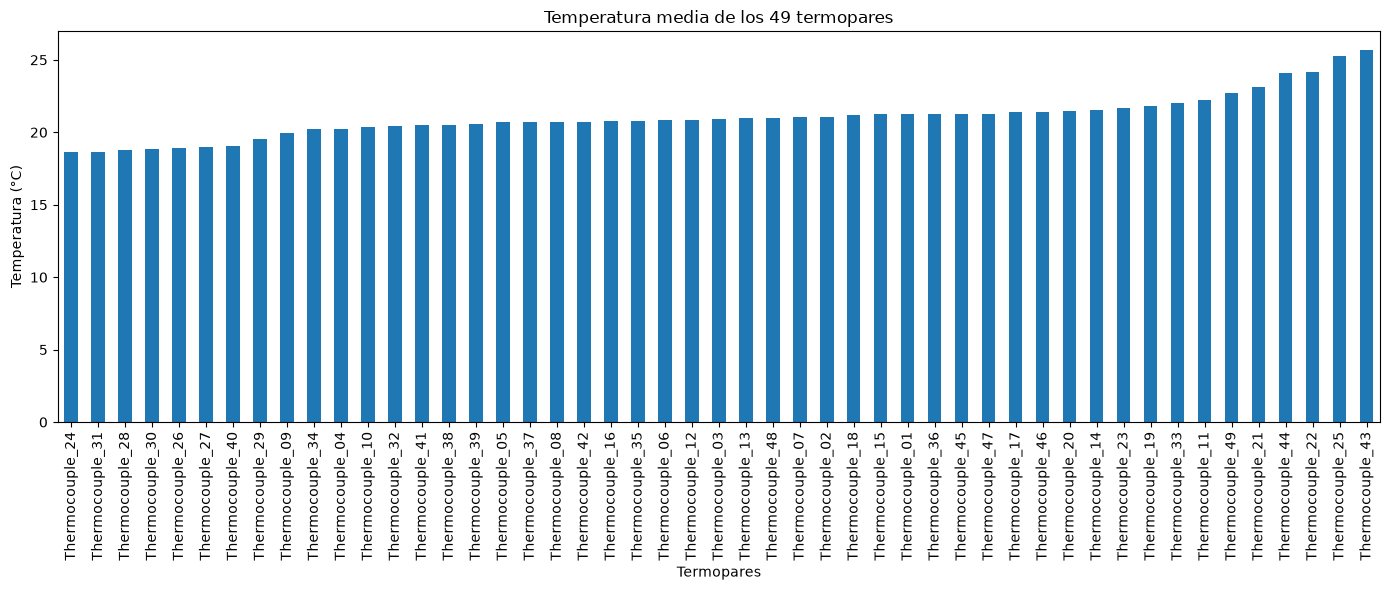

In [51]:
# Representamos la temperatura media de cada termopar

temperaturas_medias.sort_values().plot(
    kind="bar",
    figsize=(14, 6),
    title="Temperatura media de los 49 termopares",
    ylabel="Temperatura (°C)",
    xlabel="Termopares"
)

plt.tight_layout()
plt.show()

In [52]:
# Calculamos la desviación estándar de cada termopar

variabilidad_temperaturas = subset_termopares.std()

print(variabilidad_temperaturas.sort_values(ascending=False))

Thermocouple_44   7.015
Thermocouple_43   6.447
Thermocouple_25   5.285
Thermocouple_32   4.185
Thermocouple_22   3.586
Thermocouple_11   2.631
Thermocouple_24   2.322
Thermocouple_21   2.293
Thermocouple_49   2.148
Thermocouple_48   2.103
Thermocouple_15   1.797
Thermocouple_19   1.738
Thermocouple_16   1.724
Thermocouple_23   1.681
Thermocouple_47   1.642
Thermocouple_08   1.609
Thermocouple_14   1.576
Thermocouple_36   1.561
Thermocouple_18   1.461
Thermocouple_46   1.417
Thermocouple_33   1.416
Thermocouple_20   1.402
Thermocouple_03   1.354
Thermocouple_02   1.346
Thermocouple_01   1.280
Thermocouple_12   1.271
Thermocouple_07   1.256
Thermocouple_17   1.232
Thermocouple_13   1.201
Thermocouple_42   1.167
Thermocouple_45   1.156
Thermocouple_35   1.126
Thermocouple_10   1.072
Thermocouple_40   1.056
Thermocouple_05   1.055
Thermocouple_04   0.986
Thermocouple_28   0.978
Thermocouple_29   0.973
Thermocouple_06   0.920
Thermocouple_27   0.915
Thermocouple_26   0.914
Thermocouple_41 

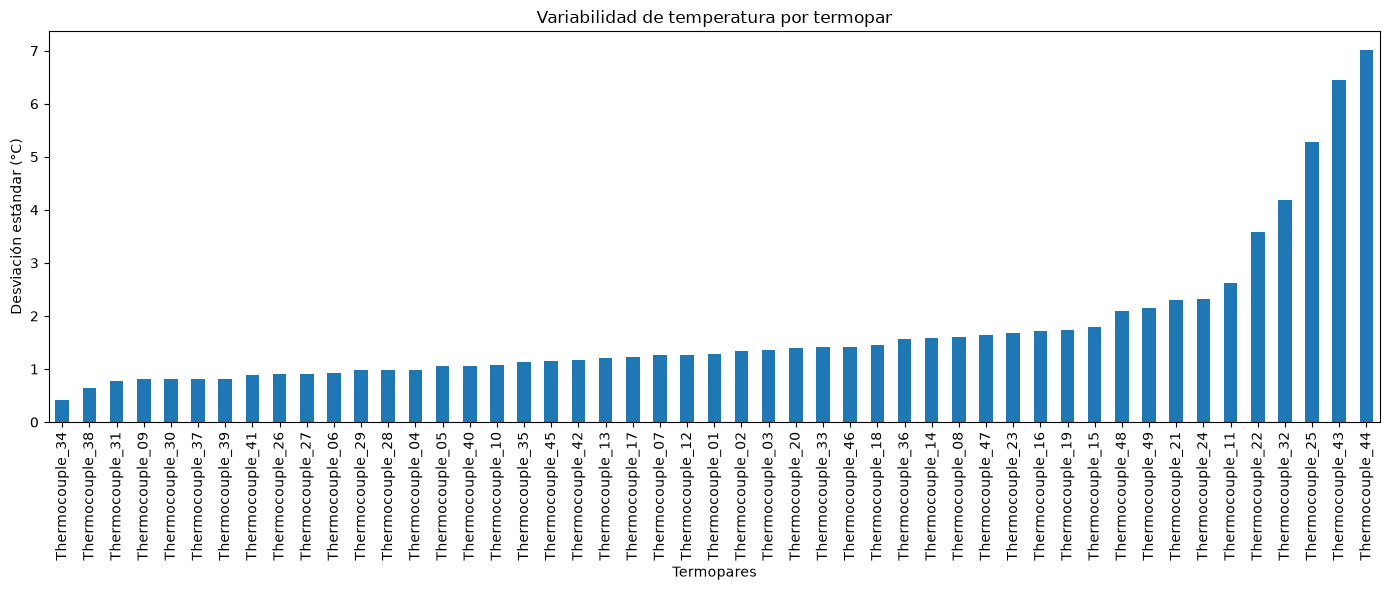

In [53]:
# Representamos la variabilidad de cada termopar

variabilidad_temperaturas.sort_values().plot(
    kind="bar",
    figsize=(14, 6),
    title="Variabilidad de temperatura por termopar",
    ylabel="Desviación estándar (°C)",
    xlabel="Termopares"
)

plt.tight_layout()
plt.show()

In [54]:
# Calculamos la temperatura máxima registrada por cada termopar

temperaturas_maximas = subset_termopares.max()

print(temperaturas_maximas.sort_values(ascending=False))

Thermocouple_44   56.900
Thermocouple_43   42.900
Thermocouple_25   36.900
Thermocouple_22   36.400
Thermocouple_32   35.400
Thermocouple_11   30.200
Thermocouple_21   28.900
Thermocouple_23   27.600
Thermocouple_49   26.300
Thermocouple_24   25.100
Thermocouple_16   24.900
Thermocouple_14   24.700
Thermocouple_47   24.600
Thermocouple_48   24.600
Thermocouple_19   24.600
Thermocouple_33   24.500
Thermocouple_36   24.400
Thermocouple_17   24.400
Thermocouple_08   24.300
Thermocouple_01   24.200
Thermocouple_15   24.200
Thermocouple_46   24.100
Thermocouple_07   24.100
Thermocouple_02   24.000
Thermocouple_12   24.000
Thermocouple_20   23.900
Thermocouple_03   23.800
Thermocouple_18   23.700
Thermocouple_13   23.100
Thermocouple_45   23.100
Thermocouple_06   22.900
Thermocouple_05   22.900
Thermocouple_35   22.800
Thermocouple_10   22.800
Thermocouple_42   22.600
Thermocouple_41   22.400
Thermocouple_04   22.400
Thermocouple_39   22.100
Thermocouple_37   21.900
Thermocouple_09   21.900


In [55]:
# Reunimos las principales estadísticas de temperatura

resumen_termopares = pd.DataFrame({
    "Temperatura_media": temperaturas_medias,
    "Temperatura_maxima": temperaturas_maximas,
    "Desviacion_estandar": variabilidad_temperaturas
})

print(resumen_termopares.sort_values(
    "Temperatura_maxima",
    ascending=False
))

                 Temperatura_media  Temperatura_maxima  Desviacion_estandar
Thermocouple_44             24.095              56.900                7.015
Thermocouple_43             25.684              42.900                6.447
Thermocouple_25             25.243              36.900                5.285
Thermocouple_22             24.159              36.400                3.586
Thermocouple_32             20.406              35.400                4.185
Thermocouple_11             22.229              30.200                2.631
Thermocouple_21             23.159              28.900                2.293
Thermocouple_23             21.677              27.600                1.681
Thermocouple_49             22.735              26.300                2.148
Thermocouple_24             18.624              25.100                2.322
Thermocouple_16             20.764              24.900                1.724
Thermocouple_14             21.545              24.700                1.576
Thermocouple

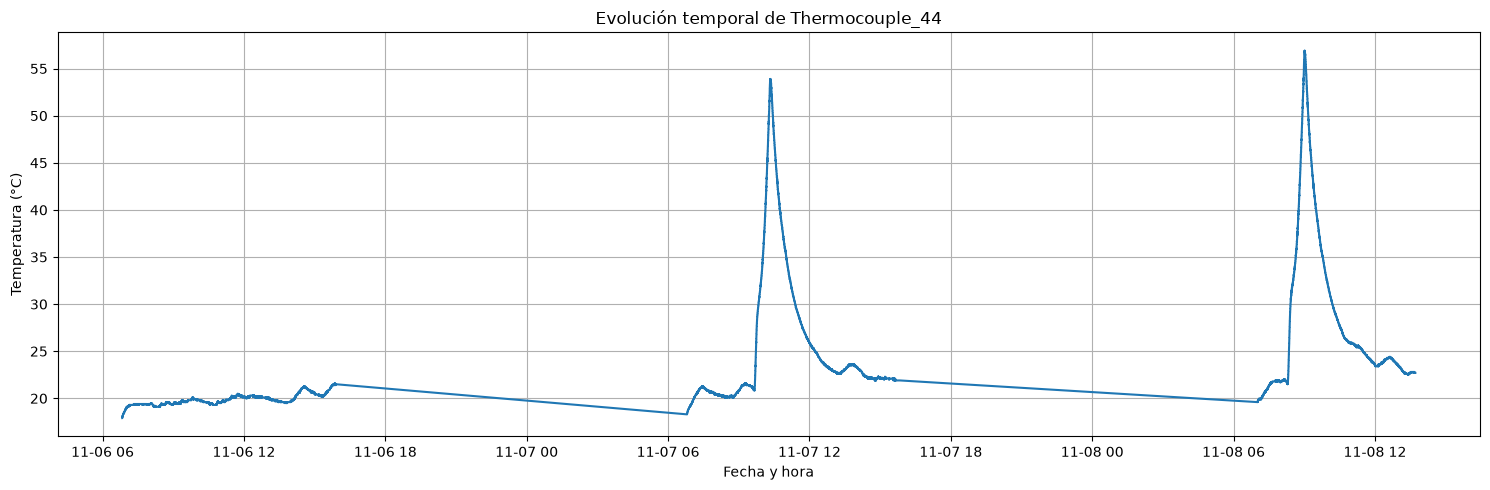

In [56]:
# Representamos la evolución temporal de Thermocouple_44

plt.figure(figsize=(15, 5))

plt.plot(
    sensores["Date"],
    sensores["Thermocouple_44"]
)

plt.title("Evolución temporal de Thermocouple_44")
plt.xlabel("Fecha y hora")
plt.ylabel("Temperatura (°C)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [57]:
# Localizamos los registros con las temperaturas máximas

indices_maximos = sensores["Thermocouple_44"].nlargest(5).index

print(
    sensores.loc[
        indices_maximos,
        ["Date", "Thermocouple_44"]
    ]
)

                     Date  Thermocouple_44
72469 2024-11-08 09:00:43           56.900
72470 2024-11-08 09:00:44           56.900
72471 2024-11-08 09:00:45           56.900
72472 2024-11-08 09:00:46           56.900
72473 2024-11-08 09:00:47           56.900


In [58]:
# Identificamos la temperatura máxima de cada día

sensores["Dia"] = sensores["Date"].dt.date

indices_maximos_dia = sensores.groupby("Dia")["Thermocouple_44"].idxmax()

maximos_diarios = sensores.loc[
    indices_maximos_dia,
    ["Date", "Thermocouple_44"]
]

print(maximos_diarios)

                     Date  Thermocouple_44
32444 2024-11-06 15:50:54           21.600
45309 2024-11-07 10:19:57           53.900
72469 2024-11-08 09:00:43           56.900


In [59]:
# Calculamos las estadísticas principales de los sensores IDS

resumen_ids = subset_ids.agg(["min", "max", "mean", "std"]).T

# Calculamos el rango de variación de cada sensor
resumen_ids["Rango"] = resumen_ids["max"] - resumen_ids["min"]

print(resumen_ids.sort_values("Rango", ascending=False))

             min       max      mean    std   Rango
Bar_05 63110.070 63281.630 63205.964 67.082 171.560
Bar_01 58820.200 58967.590 58904.206 37.532 147.390
Bar_09 59833.280 59937.100 59887.312 32.104 103.820
Bar_02 61091.540 61186.390 61143.249 27.039  94.850
Bar_04 58359.460 58433.040 58399.072 19.914  73.580
Bar_03 60251.140 60314.070 60284.007 19.100  62.930
Bar_08 60650.430 60692.010 60671.224 11.746  41.580
Bar_14 58578.630 58616.300 58600.604  9.335  37.670
Bar_06 61862.340 61892.010 61876.094  9.010  29.670
Bar_11 58119.480 58146.140 58131.446  7.934  26.660
Bar_07 58723.050 58749.220 58737.599  7.127  26.170
Bar_12 59687.740 59705.260 59698.170  4.818  17.520
Bar_13 60960.190 60970.700 60965.345  2.964  10.510
Bar_10 61353.880 61362.230 61358.667  1.969   8.350


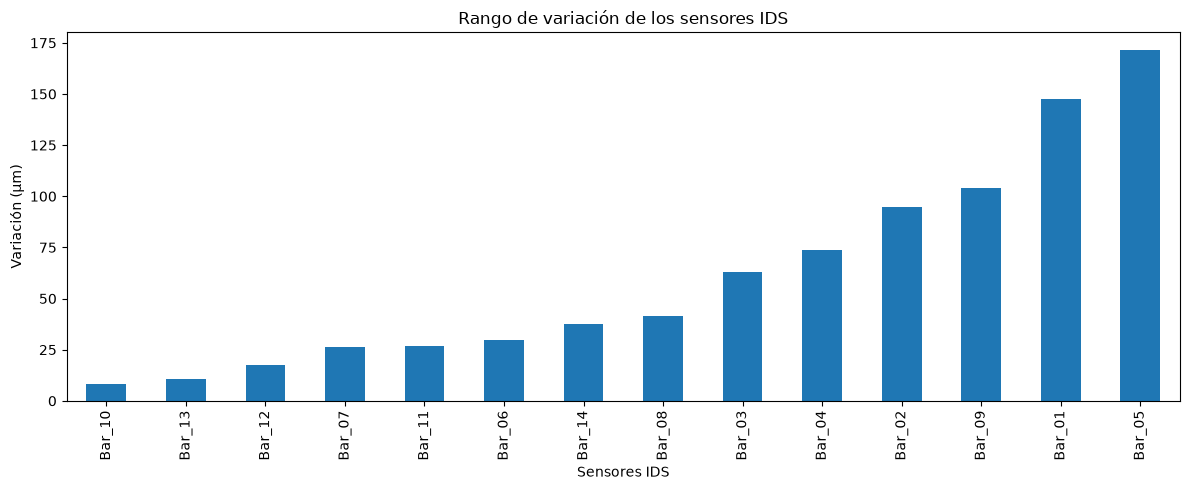

In [60]:
# Representamos el rango de variación de cada sensor IDS

resumen_ids["Rango"].sort_values().plot(
    kind="bar",
    figsize=(12, 5),
    title="Rango de variación de los sensores IDS",
    ylabel="Variación (µm)",
    xlabel="Sensores IDS"
)

plt.tight_layout()
plt.show()

In [61]:
# Calcular la temperatura media de los 49 termopares en cada instante

sensores["Temperatura_media"] = subset_termopares.mean(axis=1)

# Seleccionar las variables del husillo y la referencia temporal

datos_husillo = cnc[
    [
        "Timestamp",
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity"
    ]
].copy()

# Seleccionar la referencia temporal y la temperatura media

datos_temperatura = sensores[
    ["Timestamp", "Temperatura_media"]
].copy()

In [62]:
# Calcular la temperatura media de los 49 termopares en cada instante

sensores["Temperatura_media"] = subset_termopares.mean(axis=1)

In [63]:
# Seleccionar las variables del husillo

datos_husillo = cnc[
    [
        "Timestamp",
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity"
    ]
].copy()

# Seleccionar la temperatura media de los sensores

datos_temperatura = sensores[
    ["Timestamp", "Temperatura_media"]
].copy()

In [64]:
print("Variables del husillo:")
print(datos_husillo.head())

print("\nTemperatura media:")
print(datos_temperatura.head())

Variables del husillo:
       Timestamp  SPActualSpeed  SPAxisPower  SPAxisIntensity
0 1730875667.362          0.000        0.000            0.000
1 1730875668.362          0.000        0.000            0.000
2 1730875669.363          0.000        0.000            0.000
3 1730875670.362          0.000       -0.000            0.000
4 1730875671.362          0.000       -0.000            0.000

Temperatura media:
    Timestamp  Temperatura_media
0  1730875807             17.606
1  1730875808             17.610
2  1730875809             17.608
3  1730875810             17.616
4  1730875811             17.614


In [65]:
# Redondear el timestamp del CNC al segundo más cercano

datos_husillo["Timestamp"] = datos_husillo["Timestamp"].round().astype(int)

# Unir las variables del husillo con la temperatura media

datos_h2 = pd.merge(
    datos_husillo,
    datos_temperatura,
    on="Timestamp",
    how="inner"
)

print("Registros sincronizados:", len(datos_h2))
print(datos_h2.head())

Registros sincronizados: 89215
    Timestamp  SPActualSpeed  SPAxisPower  SPAxisIntensity  Temperatura_media
0  1730875807          0.000        0.000           70.500             17.606
1  1730875808          0.000        0.000           70.497             17.610
2  1730875809          0.000        0.000           70.497             17.608
3  1730875810          0.000        0.000           70.504             17.616
4  1730875811          0.000       -0.000           70.491             17.614


In [66]:
# Estadísticas descriptivas de las variables del husillo y la temperatura

datos_h2[
    [
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity",
        "Temperatura_media"
    ]
].describe().round(2)

,SPActualSpeed,SPAxisPower,SPAxisIntensity,Temperatura_media
count,89215.000,89215.000,89215.000,89215.000
mean,-0.440,0.000,48.740,21.050
std,5.330,0.010,32.580,1.330
min,-100.000,-0.140,0.000,17.610
25%,0.000,-0.000,0.000,19.670
50%,0.000,0.000,70.490,21.740
75%,0.000,0.000,70.500,22.150
max,100.000,0.310,151.560,23.110


In [67]:
# Contar registros con valores distintos de cero

for columna in ["SPActualSpeed", "SPAxisPower", "SPAxisIntensity"]:

    registros_activos = (datos_h2[columna] != 0).sum()

    porcentaje = registros_activos / len(datos_h2) * 100

    print(
        f"{columna}: {registros_activos} registros "
        f"({porcentaje:.2f} %)"
    )

SPActualSpeed: 4684 registros (5.25 %)
SPAxisPower: 89215 registros (100.00 %)
SPAxisIntensity: 61671 registros (69.13 %)


In [68]:
# Examinar los valores más frecuentes de las variables del husillo

for columna in ["SPActualSpeed", "SPAxisPower", "SPAxisIntensity"]:

    print(f"\n{columna}")
    print(datos_h2[columna].value_counts().head(10))


SPActualSpeed
SPActualSpeed
0.000       84531
-8.828       1313
-8.828        720
-8.828        235
-8.828        150
-8.828        125
-100.000      123
-8.828        113
-10.594       106
-8.828         53
Name: count, dtype: int64

SPAxisPower
SPAxisPower
0.000     100
0.000      47
0.000      42
0.000      35
0.000      33
0.000      33
0.000      31
-0.000     30
0.000      29
0.000      29
Name: count, dtype: int64

SPAxisIntensity
SPAxisIntensity
0.000     27544
70.500       69
70.498       65
70.498       64
70.497       61
70.498       60
70.497       60
70.498       59
70.496       57
70.493       54
Name: count, dtype: int64


In [69]:
# Examinar los rangos de valores absolutos

datos_h2[
    ["SPActualSpeed", "SPAxisPower", "SPAxisIntensity"]
].abs().describe().round(4)

,SPActualSpeed,SPAxisPower,SPAxisIntensity
count,89215.000,89215.000,89215.000
mean,0.666,0.000,48.738
std,5.302,0.007,32.576
min,0.000,0.000,0.000
25%,0.000,0.000,0.000
50%,0.000,0.000,70.492
75%,0.000,0.000,70.501
max,100.000,0.311,151.561


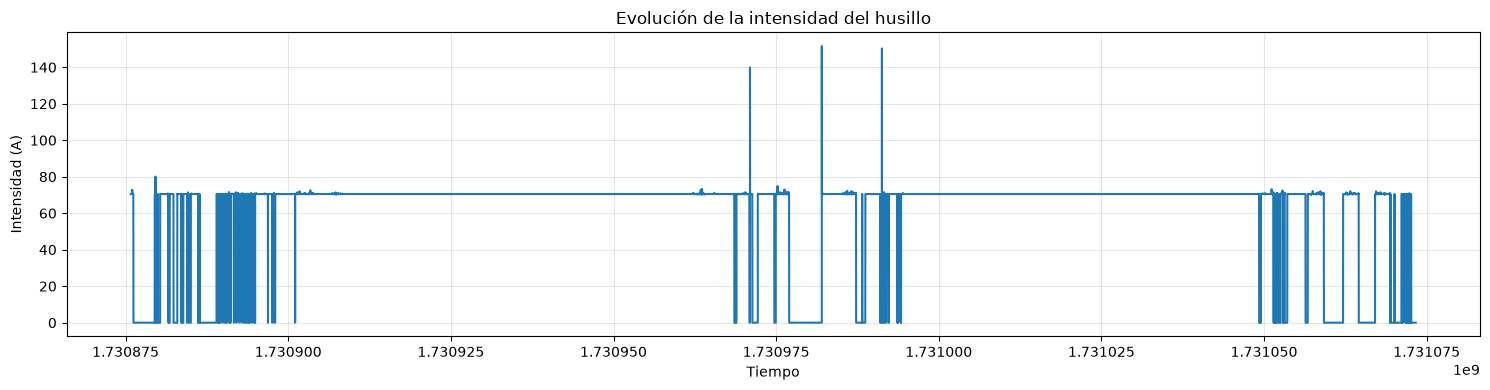

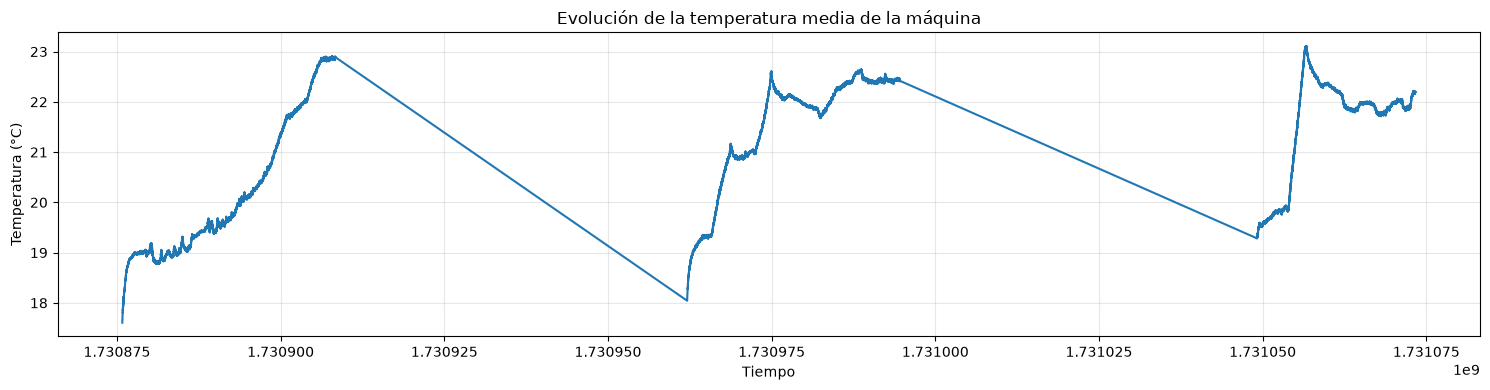

In [70]:
# Evolución temporal de la intensidad del husillo

plt.figure(figsize=(15, 4))

plt.plot(
    datos_h2["Timestamp"],
    datos_h2["SPAxisIntensity"]
)

plt.title("Evolución de la intensidad del husillo")
plt.xlabel("Tiempo")
plt.ylabel("Intensidad (A)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Evolución temporal de la temperatura media

plt.figure(figsize=(15, 4))

plt.plot(
    datos_h2["Timestamp"],
    datos_h2["Temperatura_media"]
)

plt.title("Evolución de la temperatura media de la máquina")
plt.xlabel("Tiempo")
plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

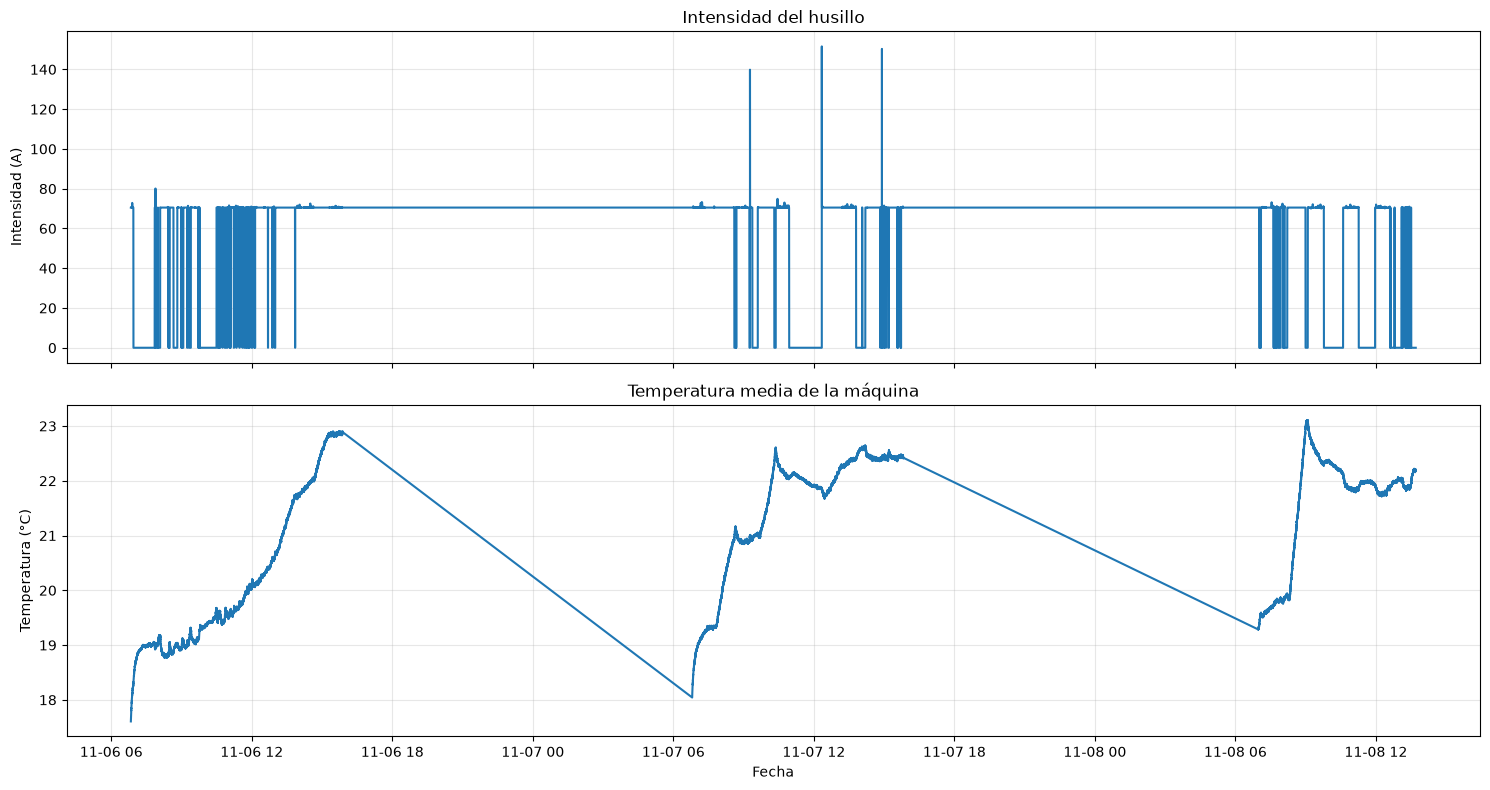

In [71]:
# Convertir el timestamp a fecha y hora

datos_h2["Fecha"] = pd.to_datetime(
    datos_h2["Timestamp"],
    unit="s"
)

# Crear dos gráficos con fechas legibles

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

axes[0].plot(datos_h2["Fecha"], datos_h2["SPAxisIntensity"])
axes[0].set_title("Intensidad del husillo")
axes[0].set_ylabel("Intensidad (A)")
axes[0].grid(alpha=0.3)

axes[1].plot(datos_h2["Fecha"], datos_h2["Temperatura_media"])
axes[1].set_title("Temperatura media de la máquina")
axes[1].set_ylabel("Temperatura (°C)")
axes[1].set_xlabel("Fecha")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [72]:
# Calcular correlación entre intensidad y temperatura media

correlacion_h2 = datos_h2[
    ["SPAxisIntensity", "Temperatura_media"]
].corr()

print(correlacion_h2.round(3))

                   SPAxisIntensity  Temperatura_media
SPAxisIntensity              1.000              0.035
Temperatura_media            0.035              1.000


In [73]:
# Comparar temperatura según la actividad registrada del husillo

datos_h2["Estado_husillo"] = np.where(
    datos_h2["SPAxisIntensity"] == 0,
    "Intensidad cero",
    "Intensidad distinta de cero"
)

comparacion_h2 = datos_h2.groupby("Estado_husillo")["Temperatura_media"].agg(
    ["count", "mean", "std", "min", "max"]
)

print(comparacion_h2.round(2))

                             count   mean   std    min    max
Estado_husillo                                               
Intensidad cero              27544 20.980 1.410 18.290 23.110
Intensidad distinta de cero  61671 21.080 1.300 17.610 23.110


In [74]:
# Incorporar la temperatura del termopar 44 a los datos sincronizados

datos_h2 = datos_h2.merge(
    sensores[["Timestamp", "Thermocouple_44"]],
    on="Timestamp",
    how="left"
)

# Calcular la correlación con la intensidad del husillo

print(
    datos_h2[["SPAxisIntensity", "Thermocouple_44"]]
    .corr()
    .round(3)
)

                 SPAxisIntensity  Thermocouple_44
SPAxisIntensity            1.000           -0.027
Thermocouple_44           -0.027            1.000


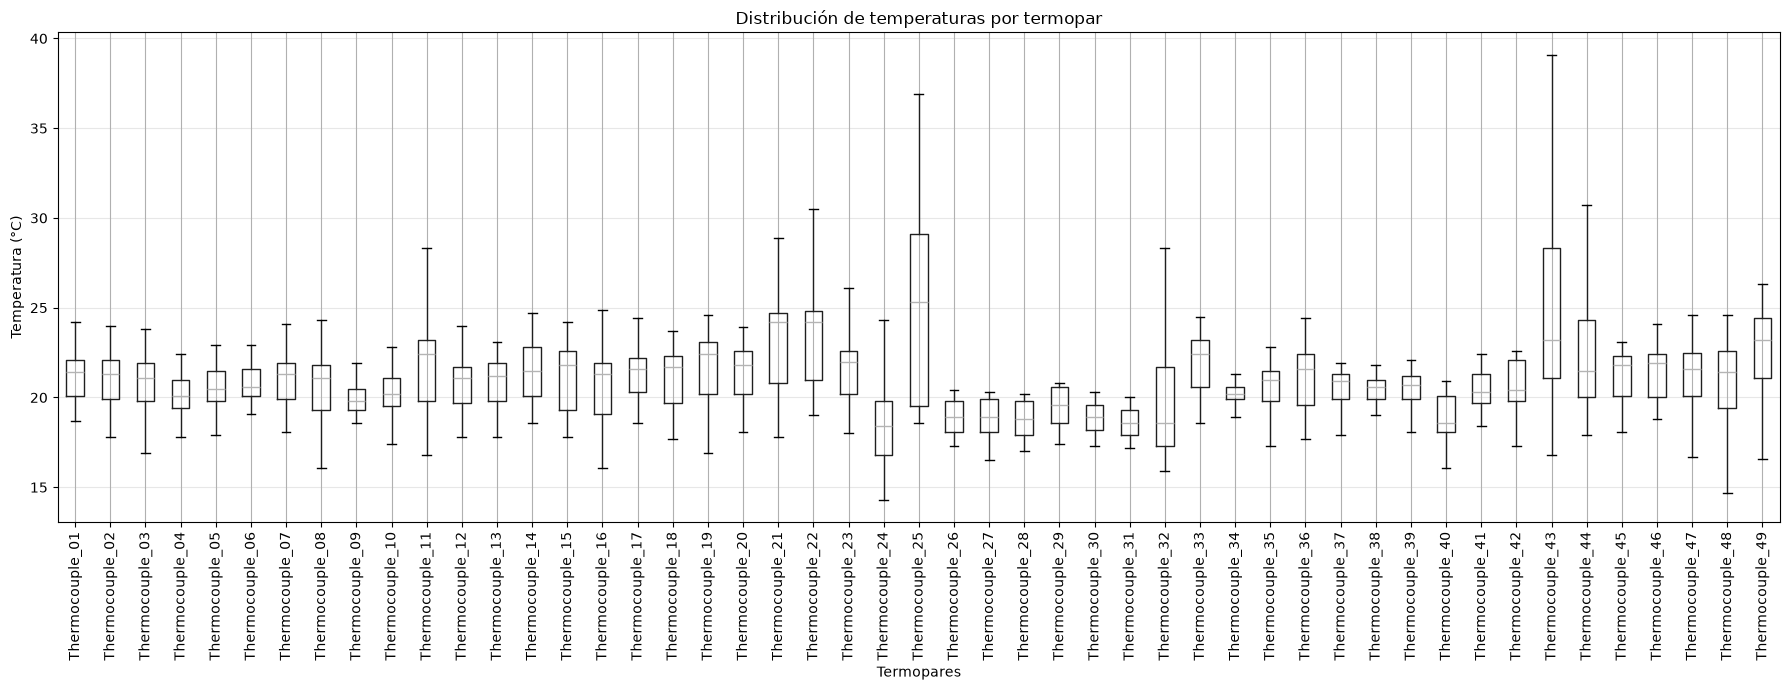

In [75]:
# Comparar la distribución de temperaturas de los 49 termopares

plt.figure(figsize=(18, 7))

subset_termopares.boxplot(
    rot=90,
    showfliers=False
)

plt.title("Distribución de temperaturas por termopar")
plt.xlabel("Termopares")
plt.ylabel("Temperatura (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [77]:
# Identificar los termopares con mayor y menor variabilidad

variabilidad = subset_termopares.std().sort_values(ascending=False)

print("10 termopares con mayor variabilidad:")
print(variabilidad.head(10).round(2))

print("\n10 termopares con menor variabilidad:")
print(variabilidad.tail(10).sort_values().round(2))

10 termopares con mayor variabilidad:
Thermocouple_44   7.010
Thermocouple_43   6.450
Thermocouple_25   5.280
Thermocouple_32   4.190
Thermocouple_22   3.590
Thermocouple_11   2.630
Thermocouple_24   2.320
Thermocouple_21   2.290
Thermocouple_49   2.150
Thermocouple_48   2.100
dtype: float64

10 termopares con menor variabilidad:
Thermocouple_34   0.420
Thermocouple_38   0.650
Thermocouple_31   0.780
Thermocouple_09   0.810
Thermocouple_30   0.810
Thermocouple_37   0.810
Thermocouple_39   0.820
Thermocouple_41   0.880
Thermocouple_26   0.910
Thermocouple_27   0.920
dtype: float64


### H3. Diferencias térmicas entre los puntos de medición

El análisis exploratorio de los 49 termopares muestra diferencias significativas en sus distribuciones y variabilidad térmica durante los ensayos.

Los termopares 44, 43 y 25 presentan las mayores desviaciones estándar, con valores de 7,01 °C, 6,45 °C y 5,28 °C, respectivamente. Por el contrario, los termopares 34, 38 y 31 presentan una variabilidad mucho menor.

Estos resultados respaldan inicialmente la hipótesis H3, al mostrar que los distintos puntos de medición presentan comportamientos térmicos diferenciados.

No obstante, para atribuir estas diferencias a componentes o zonas físicas concretas sería necesario disponer del plano de ubicación de los termopares.

In [80]:
# Reconstruir la tabla sincronizada sin columnas duplicadas

datos_h2 = pd.merge(
    datos_husillo,
    datos_temperatura,
    on="Timestamp",
    how="inner"
)

# Incorporar los tres termopares seleccionados

datos_h2 = pd.merge(
    datos_h2,
    sensores[
        [
            "Timestamp",
            "Thermocouple_43",
            "Thermocouple_44",
            "Thermocouple_25"
        ]
    ],
    on="Timestamp",
    how="inner"
)

print("Dimensiones de datos_h2:", datos_h2.shape)
print(datos_h2.head())

Dimensiones de datos_h2: (89223, 8)
    Timestamp  SPActualSpeed  SPAxisPower  SPAxisIntensity  Temperatura_media  \
0  1730875807          0.000        0.000           70.500             17.606   
1  1730875808          0.000        0.000           70.497             17.610   
2  1730875809          0.000        0.000           70.497             17.608   
3  1730875810          0.000        0.000           70.504             17.616   
4  1730875811          0.000       -0.000           70.491             17.614   

   Thermocouple_43  Thermocouple_44  Thermocouple_25  
0           16.800           17.900           18.600  
1           16.800           17.900           18.600  
2           16.800           17.900           18.600  
3           16.800           17.900           18.600  
4           16.800           17.900           18.600  


In [81]:
# Analizar la relación entre intensidad y temperaturas localizadas

correlaciones_h2 = datos_h2[
    [
        "SPAxisIntensity",
        "Thermocouple_43",
        "Thermocouple_44",
        "Thermocouple_25"
    ]
].corr()

print(correlaciones_h2.round(3))

                 SPAxisIntensity  Thermocouple_43  Thermocouple_44  \
SPAxisIntensity            1.000           -0.138           -0.027   
Thermocouple_43           -0.138            1.000            0.881   
Thermocouple_44           -0.027            0.881            1.000   
Thermocouple_25            0.172            0.468            0.402   

                 Thermocouple_25  
SPAxisIntensity            0.172  
Thermocouple_43            0.468  
Thermocouple_44            0.402  
Thermocouple_25            1.000  


In [82]:
# Comprobar la correlación considerando posibles retardos térmicos

retardos = [0, 300, 600, 1800, 3600]

for segundos in retardos:

    correlacion = datos_h2["SPAxisIntensity"].corr(
        datos_h2["Thermocouple_25"].shift(-segundos)
    )

    print(f"Retardo de {segundos // 60} minutos: {correlacion:.3f}")

Retardo de 0 minutos: 0.172
Retardo de 5 minutos: 0.186
Retardo de 10 minutos: 0.201
Retardo de 30 minutos: 0.217
Retardo de 60 minutos: 0.171


In [83]:
# Seleccionar los registros del 7 de noviembre

datos_h2["Fecha"] = pd.to_datetime(
    datos_h2["Timestamp"],
    unit="s"
)

dia_7 = datos_h2[
    datos_h2["Fecha"].dt.date == pd.Timestamp("2024-11-07").date()
].copy()

print("Registros del día 7:", len(dia_7))

Registros del día 7: 32457


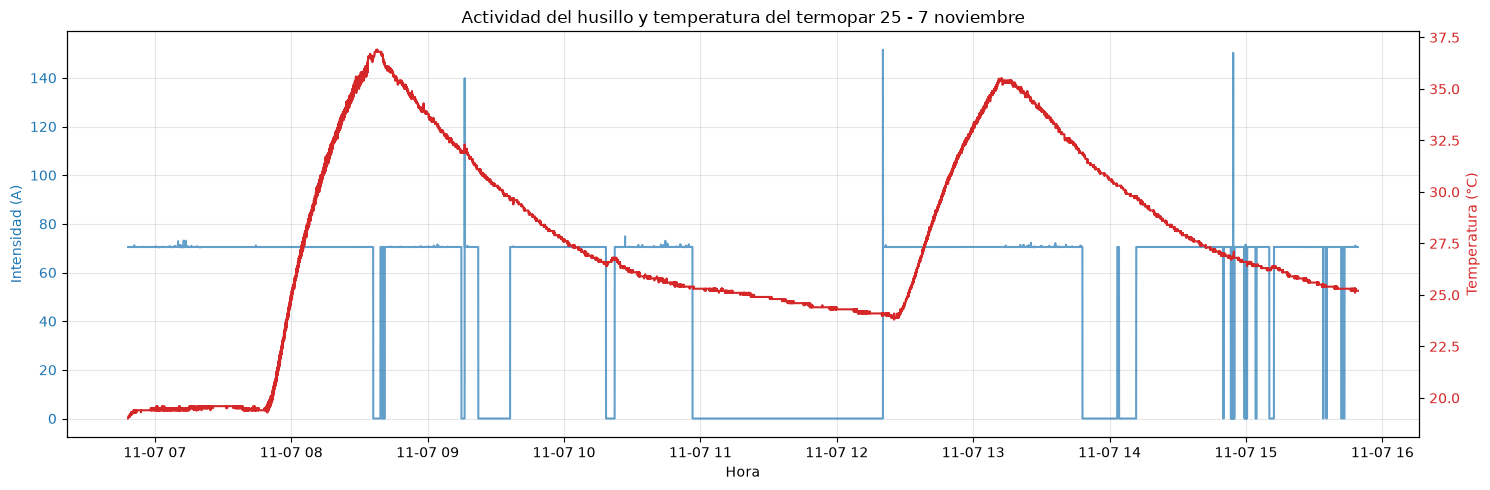

In [84]:
# Representar intensidad del husillo y temperatura del termopar 25

fig, ax1 = plt.subplots(figsize=(15, 5))

# Intensidad del husillo
ax1.plot(
    dia_7["Fecha"],
    dia_7["SPAxisIntensity"],
    color="tab:blue",
    alpha=0.7,
    label="Intensidad del husillo"
)

ax1.set_xlabel("Hora")
ax1.set_ylabel("Intensidad (A)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(alpha=0.3)

# Temperatura del termopar 25
ax2 = ax1.twinx()

ax2.plot(
    dia_7["Fecha"],
    dia_7["Thermocouple_25"],
    color="tab:red",
    label="Thermocouple 25"
)

ax2.set_ylabel("Temperatura (°C)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.title("Actividad del husillo y temperatura del termopar 25 - 7 noviembre")
fig.tight_layout()
plt.show()

In [85]:
# Comparar velocidad e intensidad del husillo

print(
    datos_h2[
        ["SPActualSpeed", "SPAxisIntensity"]
    ].describe().round(2)
)

print("\nVelocidad e intensidad cuando la velocidad es cero:")

print(
    datos_h2.loc[
        datos_h2["SPActualSpeed"] == 0,
        ["SPActualSpeed", "SPAxisIntensity"]
    ]["SPAxisIntensity"].describe().round(2)
)

       SPActualSpeed  SPAxisIntensity
count      89223.000        89223.000
mean          -0.440           48.730
std            5.330           32.580
min         -100.000            0.000
25%            0.000            0.000
50%            0.000           70.490
75%            0.000           70.500
max          100.000          151.560

Velocidad e intensidad cuando la velocidad es cero:
count   84539.000
mean       47.530
std        33.050
min         0.000
25%         0.000
50%        70.490
75%        70.500
max       151.560
Name: SPAxisIntensity, dtype: float64


In [86]:
# Comparar intensidad según la velocidad del husillo

datos_h2.groupby(
    datos_h2["SPActualSpeed"] == 0
)["SPAxisIntensity"].agg(
    ["count", "mean", "std", "min", "max"]
).round(3)

,count,mean,std,min,max
SPActualSpeed,,,,,
False,4684,70.458,1.785,0.000,72.046
True,84539,47.529,33.050,0.000,151.561


In [87]:
# Valores de intensidad más frecuentes cuando la velocidad es cero

print(
    datos_h2.loc[
        datos_h2["SPActualSpeed"] == 0,
        "SPAxisIntensity"
    ].value_counts().head(10)
)

SPAxisIntensity
0.000     27549
70.500       63
70.498       62
70.498       61
70.497       58
70.498       56
70.498       55
70.497       55
70.496       54
70.498       50
Name: count, dtype: int64


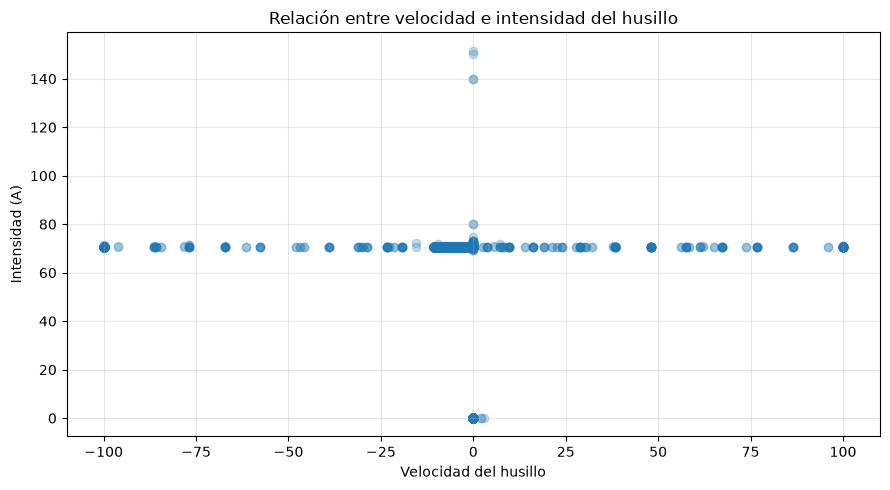

In [88]:
# Comparar velocidad e intensidad mediante un diagrama de dispersión

plt.figure(figsize=(9, 5))

plt.scatter(
    datos_h2["SPActualSpeed"],
    datos_h2["SPAxisIntensity"],
    alpha=0.25
)

plt.title("Relación entre velocidad e intensidad del husillo")
plt.xlabel("Velocidad del husillo")
plt.ylabel("Intensidad (A)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [89]:
# Examinar los valores más frecuentes de velocidad del husillo

print(
    datos_h2["SPActualSpeed"]
    .value_counts()
    .head(20)
)

SPActualSpeed
0.000       84539
-8.828       1313
-8.828        720
-8.828        235
-8.828        150
-8.828        125
-100.000      123
-8.828        113
-10.594       106
-8.828         53
100.000        44
-2.648         42
-6.621         34
-8.828         32
-6.180         31
-1.488         29
-0.883         28
-7.062         26
-8.828         26
-8.828         26
Name: count, dtype: int64


In [90]:
# Examinar la precisión y distribución de la velocidad

print("Número de valores únicos:", datos_h2["SPActualSpeed"].nunique())

print("\nValores únicos más frecuentes:")
print(
    datos_h2["SPActualSpeed"]
    .round(3)
    .value_counts()
    .head(15)
)

print("\nPercentiles:")
print(
    datos_h2["SPActualSpeed"]
    .quantile([0, 0.01, 0.25, 0.50, 0.75, 0.99, 1])
)

Número de valores únicos: 325

Valores únicos más frecuentes:
SPActualSpeed
0.000       84539
-8.828       2820
-100.000      123
-10.594       111
-6.621         60
-2.648         56
-6.180         49
-7.062         47
100.000        44
-5.297         38
-4.073         34
-0.883         33
-1.766         32
-8.387         31
-8.749         30
Name: count, dtype: int64

Percentiles:
0.000   -100.000
0.010     -8.828
0.250      0.000
0.500      0.000
0.750      0.000
0.990      0.000
1.000    100.000
Name: SPActualSpeed, dtype: float64


In [91]:
# Comparar las tres variables del husillo mediante sus valores absolutos

datos_h2[
    ["SPActualSpeed", "SPAxisPower", "SPAxisIntensity"]
].abs().describe().round(3)

,SPActualSpeed,SPAxisPower,SPAxisIntensity
count,89223.000,89223.000,89223.000
mean,0.666,0.000,48.733
std,5.302,0.007,32.577
min,0.000,0.000,0.000
25%,0.000,0.000,0.000
50%,0.000,0.000,70.492
75%,0.000,0.000,70.501
max,100.000,0.311,151.561


In [92]:
# Comprobar los valores máximos y mínimos de las tres variables

for columna in ["SPActualSpeed", "SPAxisPower", "SPAxisIntensity"]:

    print(f"\n{columna}")
    print(datos_h2[columna].value_counts().head(5))


SPActualSpeed
SPActualSpeed
0.000     84539
-8.828     1313
-8.828      720
-8.828      235
-8.828      150
Name: count, dtype: int64

SPAxisPower
SPAxisPower
0.000    100
0.000     47
0.000     42
0.000     35
0.000     33
Name: count, dtype: int64

SPAxisIntensity
SPAxisIntensity
0.000     27552
70.500       69
70.498       65
70.498       64
70.497       61
Name: count, dtype: int64


In [93]:
# Correlación entre las variables del husillo

correlaciones_husillo = datos_h2[
    [
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity"
    ]
].corr()

print(correlaciones_husillo.round(3))

                 SPActualSpeed  SPAxisPower  SPAxisIntensity
SPActualSpeed            1.000        0.017           -0.056
SPAxisPower              0.017        1.000            0.016
SPAxisIntensity         -0.056        0.016            1.000


In [94]:
# Resumen de las variables operativas del husillo

variables_husillo = [
    "SPActualSpeed",
    "SPAxisPower",
    "SPAxisIntensity",
    "SPAxisLoad"
]

print(
    cnc[variables_husillo]
    .describe()
    .round(3)
)

       SPActualSpeed  SPAxisPower  SPAxisIntensity  SPAxisLoad
count      89655.000    89655.000        89655.000   89655.000
mean          -0.440        0.000           48.759       0.034
std            5.312        0.007           32.567       0.141
min         -100.000       -0.140            0.000       0.000
25%            0.000       -0.000            0.000       0.008
50%            0.000        0.000           70.492       0.009
75%            0.000        0.000           70.501       0.010
max          100.000        0.311          151.561       8.678


In [95]:
# Correlaciones entre las variables operativas del husillo

print(
    cnc[variables_husillo]
    .corr()
    .round(3)
)

                 SPActualSpeed  SPAxisPower  SPAxisIntensity  SPAxisLoad
SPActualSpeed            1.000        0.017           -0.055      -0.038
SPAxisPower              0.017        1.000            0.016       0.091
SPAxisIntensity         -0.055        0.016            1.000       0.123
SPAxisLoad              -0.038        0.091            0.123       1.000


In [96]:
# Estadísticas descriptivas de los sensores IDS

resumen_ids = subset_ids.describe().T[
    ["mean", "std", "min", "max"]
]

print(resumen_ids.round(3))

            mean    std       min       max
Bar_01 58904.206 37.532 58820.200 58967.590
Bar_02 61143.249 27.039 61091.540 61186.390
Bar_03 60284.007 19.100 60251.140 60314.070
Bar_04 58399.072 19.914 58359.460 58433.040
Bar_05 63205.964 67.082 63110.070 63281.630
Bar_06 61876.094  9.010 61862.340 61892.010
Bar_07 58737.599  7.127 58723.050 58749.220
Bar_08 60671.224 11.746 60650.430 60692.010
Bar_09 59887.312 32.104 59833.280 59937.100
Bar_10 61358.667  1.969 61353.880 61362.230
Bar_11 58131.446  7.934 58119.480 58146.140
Bar_12 59698.170  4.818 59687.740 59705.260
Bar_13 60965.345  2.964 60960.190 60970.700
Bar_14 58600.604  9.335 58578.630 58616.300


In [97]:
# Calcular la variación de deformación respecto al primer registro

variacion_ids = subset_ids - subset_ids.iloc[0]

# Obtener el rango de variación de cada sensor

resumen_variacion_ids = pd.DataFrame({
    "Variacion_minima": variacion_ids.min(),
    "Variacion_maxima": variacion_ids.max(),
    "Variacion_final": variacion_ids.iloc[-1]
})

print(resumen_variacion_ids.round(2))

        Variacion_minima  Variacion_maxima  Variacion_final
Bar_01          -142.370             5.020          -93.400
Bar_02           -90.920             3.930          -64.720
Bar_03           -61.780             1.150          -46.410
Bar_04           -70.750             2.830          -51.820
Bar_05          -164.880             6.680         -139.700
Bar_06           -11.480            18.190           -4.950
Bar_07           -24.470             1.700          -19.430
Bar_08           -41.260             0.320          -32.180
Bar_09           -97.860             5.960          -67.680
Bar_10            -2.970             5.380           -0.350
Bar_11            -7.820            18.840           -2.370
Bar_12           -16.210             1.310          -11.820
Bar_13            -9.940             0.570           -8.330
Bar_14           -35.880             1.790          -23.140


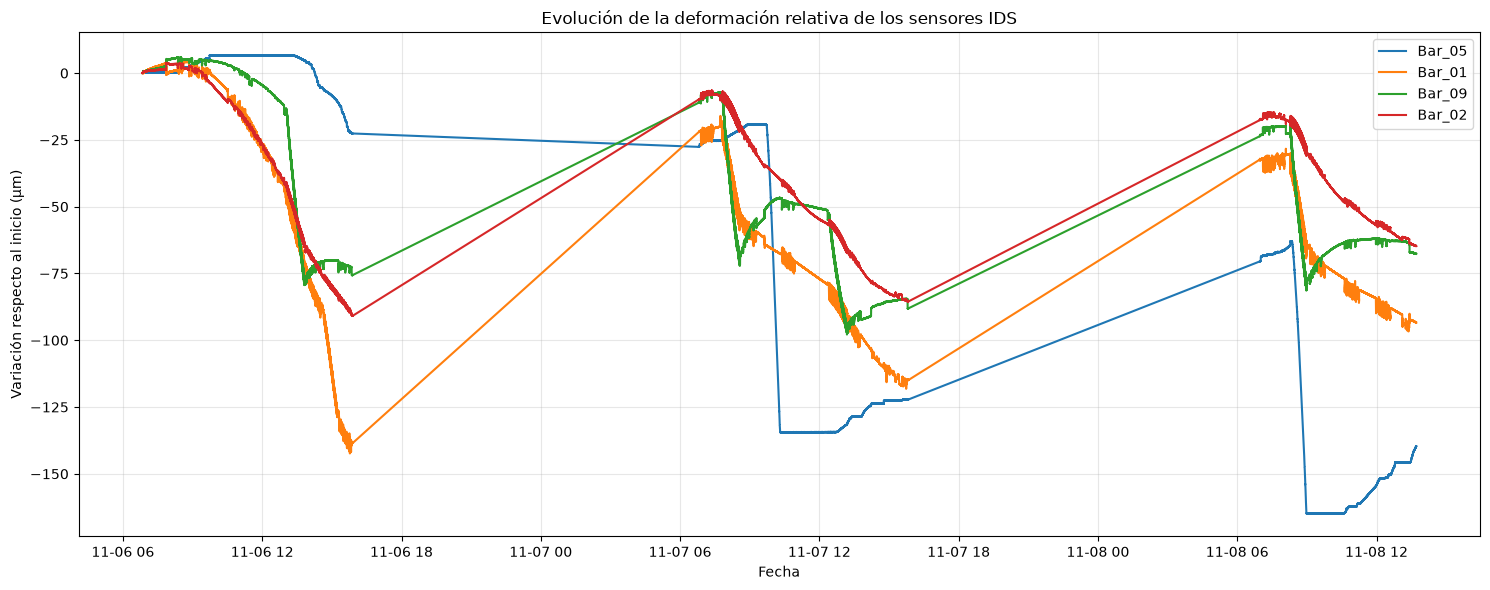

In [98]:
# Representar la evolución de los cuatro sensores IDS con mayor variación

sensores_ids_seleccionados = [
    "Bar_05",
    "Bar_01",
    "Bar_09",
    "Bar_02"
]

plt.figure(figsize=(15, 6))

for columna in sensores_ids_seleccionados:
    plt.plot(
        sensores["Date"],
        variacion_ids[columna],
        label=columna
    )

plt.title("Evolución de la deformación relativa de los sensores IDS")
plt.xlabel("Fecha")
plt.ylabel("Variación respecto al inicio (µm)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

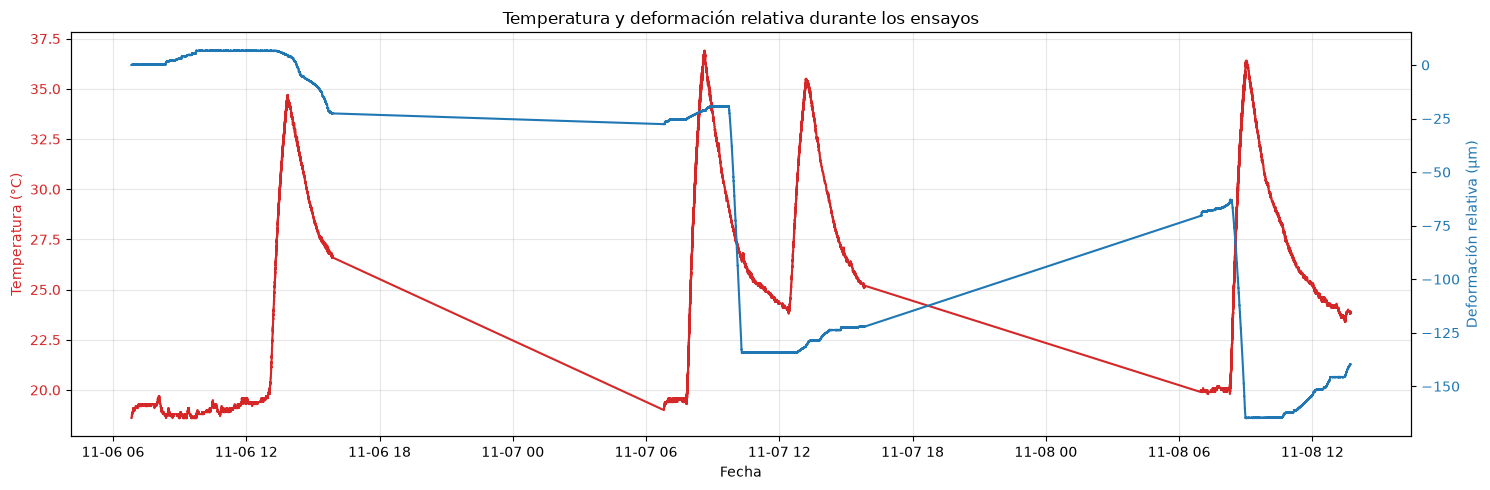

In [99]:
# Comparar temperatura y deformación durante los ensayos

fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(
    sensores["Date"],
    sensores["Thermocouple_25"],
    color="tab:red",
    label="Thermocouple_25"
)

ax1.set_xlabel("Fecha")
ax1.set_ylabel("Temperatura (°C)", color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    sensores["Date"],
    variacion_ids["Bar_05"],
    color="tab:blue",
    label="Bar_05"
)

ax2.set_ylabel("Deformación relativa (µm)", color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue")

plt.title("Temperatura y deformación relativa durante los ensayos")
fig.tight_layout()
plt.show()

In [100]:
# Seleccionar los datos del 7 de noviembre

dia_7_h1 = sensores[
    sensores["Date"].dt.date == pd.Timestamp("2024-11-07").date()
].copy()

# Calcular las variaciones respecto al primer registro de esa jornada

dia_7_h1["Variacion_temperatura"] = (
    dia_7_h1["Thermocouple_25"]
    - dia_7_h1["Thermocouple_25"].iloc[0]
)

dia_7_h1["Variacion_deformacion"] = (
    dia_7_h1["Bar_05"]
    - dia_7_h1["Bar_05"].iloc[0]
)

# Calcular correlación entre ambas variaciones

correlacion_h1 = dia_7_h1[
    ["Variacion_temperatura", "Variacion_deformacion"]
].corr()

print(correlacion_h1.round(3))

                       Variacion_temperatura  Variacion_deformacion
Variacion_temperatura                  1.000                 -0.000
Variacion_deformacion                 -0.000                  1.000


In [101]:
# Calcular correlaciones entre los 49 termopares y los 14 IDS

datos_h1 = pd.concat(
    [
        subset_termopares,
        subset_ids
    ],
    axis=1
)

correlaciones_h1 = datos_h1.corr().loc[
    subset_termopares.columns,
    subset_ids.columns
]

print(correlaciones_h1.round(2))

                 Bar_01  Bar_02  Bar_03  Bar_04  Bar_05  Bar_06  Bar_07  \
Thermocouple_01  -0.940  -0.990  -0.930  -0.900  -0.450  -0.560  -0.890   
Thermocouple_02  -0.930  -0.980  -0.920  -0.880  -0.450  -0.550  -0.880   
Thermocouple_03  -0.920  -0.980  -0.910  -0.870  -0.440  -0.530  -0.870   
Thermocouple_04  -0.950  -0.990  -0.940  -0.920  -0.500  -0.610  -0.930   
Thermocouple_05  -0.890  -0.970  -0.880  -0.850  -0.380  -0.500  -0.870   
Thermocouple_06  -0.910  -0.970  -0.900  -0.880  -0.410  -0.560  -0.900   
Thermocouple_07  -0.970  -0.970  -0.950  -0.940  -0.500  -0.580  -0.920   
Thermocouple_08  -0.940  -0.960  -0.910  -0.900  -0.440  -0.500  -0.860   
Thermocouple_09  -0.870  -0.920  -0.860  -0.850  -0.410  -0.590  -0.890   
Thermocouple_10  -0.900  -0.970  -0.890  -0.870  -0.370  -0.500  -0.880   
Thermocouple_11  -0.710  -0.560  -0.630  -0.710  -0.390  -0.370  -0.590   
Thermocouple_12  -0.970  -0.970  -0.940  -0.940  -0.490  -0.570  -0.910   
Thermocouple_13  -0.980  

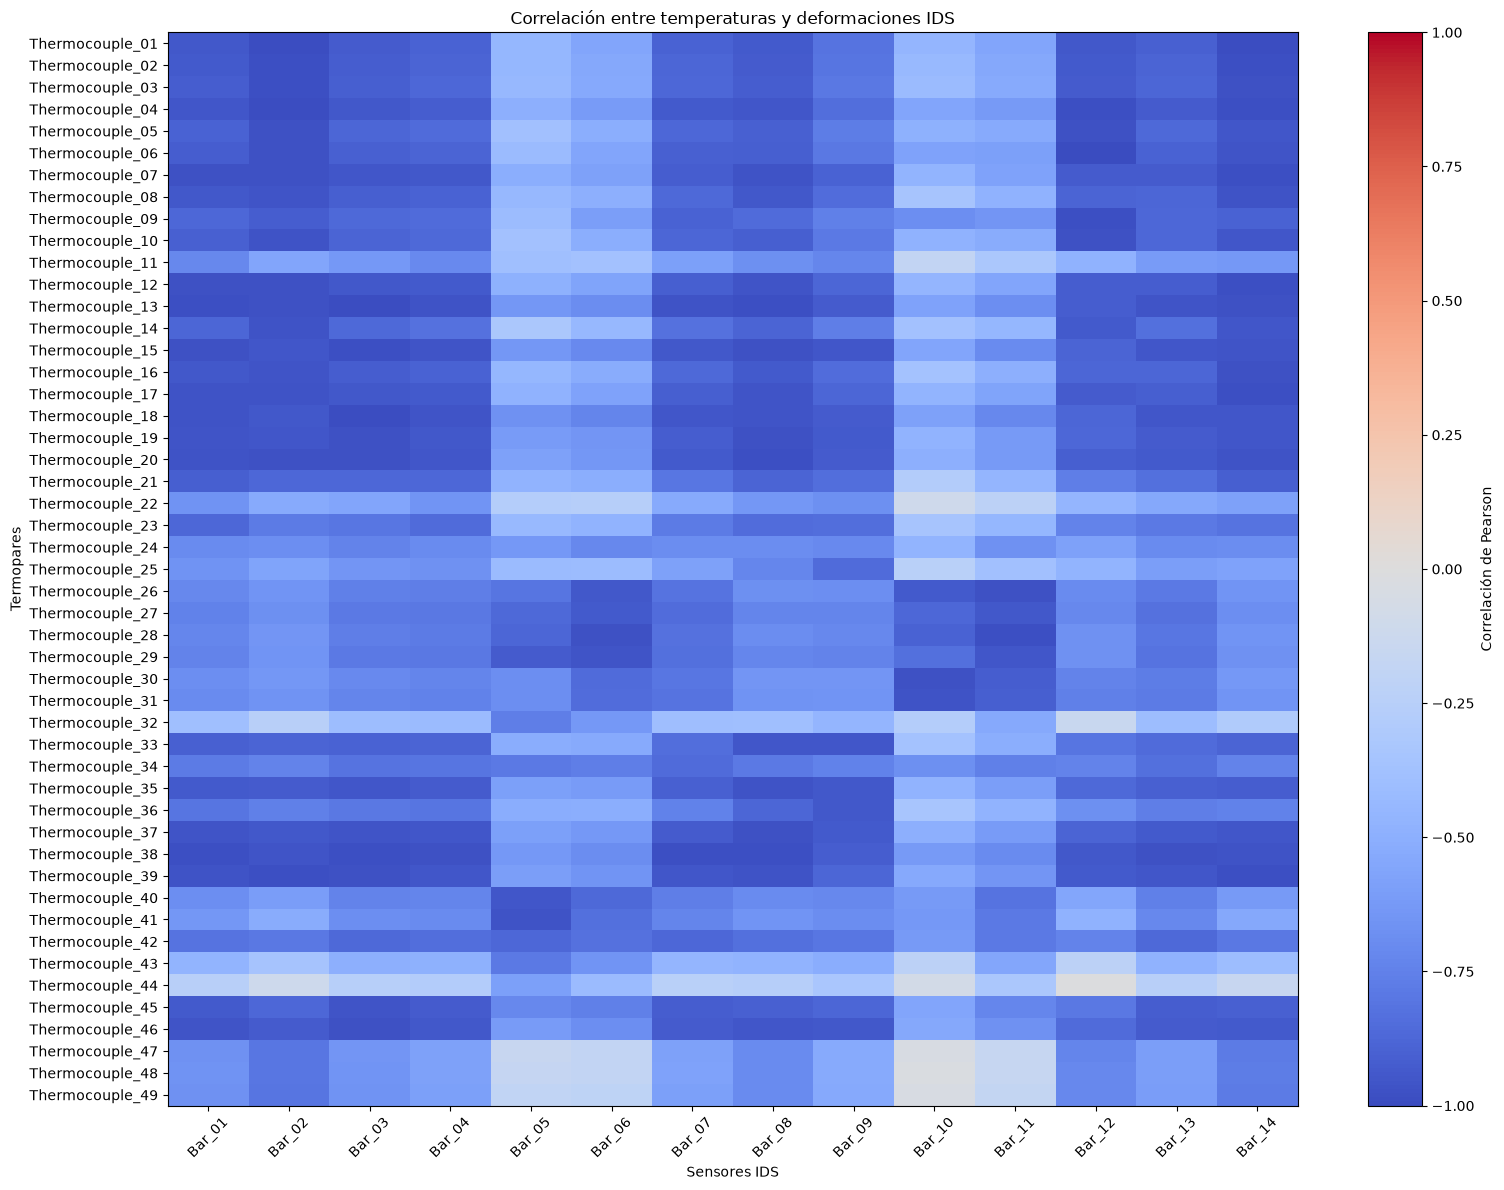

In [102]:
# Visualizar las correlaciones entre termopares e IDS

plt.figure(figsize=(16, 12))

plt.imshow(
    correlaciones_h1,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlación de Pearson")

plt.xticks(
    range(len(correlaciones_h1.columns)),
    correlaciones_h1.columns,
    rotation=45
)

plt.yticks(
    range(len(correlaciones_h1.index)),
    correlaciones_h1.index
)

plt.title("Correlación entre temperaturas y deformaciones IDS")
plt.xlabel("Sensores IDS")
plt.ylabel("Termopares")

plt.tight_layout()
plt.show()

In [103]:
# Calcular cambios entre registros consecutivos

cambios_termopares = subset_termopares.diff()
cambios_ids = subset_ids.diff()

# Calcular correlaciones entre los cambios térmicos y estructurales

correlaciones_cambios_h1 = pd.concat(
    [cambios_termopares, cambios_ids],
    axis=1
).corr().loc[
    subset_termopares.columns,
    subset_ids.columns
]

print(correlaciones_cambios_h1.round(2))

                 Bar_01  Bar_02  Bar_03  Bar_04  Bar_05  Bar_06  Bar_07  \
Thermocouple_01  -0.230  -0.330  -0.350  -0.370  -0.180   0.020  -0.330   
Thermocouple_02  -0.310  -0.430  -0.460  -0.500  -0.240   0.030  -0.430   
Thermocouple_03  -0.330  -0.470  -0.490  -0.530  -0.250   0.030  -0.470   
Thermocouple_04  -0.220  -0.320  -0.340  -0.370  -0.180   0.020  -0.320   
Thermocouple_05  -0.220  -0.310  -0.330  -0.350  -0.180   0.020  -0.310   
Thermocouple_06  -0.190  -0.290  -0.300  -0.320  -0.180   0.020  -0.280   
Thermocouple_07  -0.260  -0.400  -0.410  -0.440  -0.210   0.030  -0.390   
Thermocouple_08  -0.350  -0.520  -0.540  -0.580  -0.280   0.040  -0.510   
Thermocouple_09  -0.130  -0.190  -0.210  -0.220  -0.120   0.010  -0.190   
Thermocouple_10  -0.270  -0.380  -0.400  -0.430  -0.230   0.030  -0.380   
Thermocouple_11  -0.360  -0.500  -0.520  -0.590  -0.160   0.030  -0.490   
Thermocouple_12  -0.310  -0.450  -0.460  -0.510  -0.230   0.030  -0.440   
Thermocouple_13  -0.230  

In [104]:
# Identificar intervalos entre registros consecutivos

intervalos = sensores["Timestamp"].diff()

# Conservar únicamente cambios entre registros separados por aproximadamente 1 segundo

cambios_termopares = subset_termopares.diff().where(
    intervalos.between(0.9, 1.1)
)

cambios_ids = subset_ids.diff().where(
    intervalos.between(0.9, 1.1)
)

# Calcular correlaciones entre los cambios válidos

datos_cambios_h1 = pd.concat(
    [cambios_termopares, cambios_ids],
    axis=1
)

correlaciones_cambios_h1 = datos_cambios_h1.corr().loc[
    subset_termopares.columns,
    subset_ids.columns
]

print(correlaciones_cambios_h1.round(2))

                 Bar_01  Bar_02  Bar_03  Bar_04  Bar_05  Bar_06  Bar_07  \
Thermocouple_01   0.010  -0.000  -0.000   0.000  -0.000   0.000  -0.010   
Thermocouple_02  -0.000   0.010  -0.010  -0.010  -0.000  -0.000  -0.000   
Thermocouple_03  -0.000   0.000  -0.010   0.000   0.000  -0.000  -0.000   
Thermocouple_04   0.000   0.000  -0.010  -0.000  -0.000  -0.010  -0.000   
Thermocouple_05  -0.000   0.000  -0.000  -0.010   0.000  -0.010  -0.000   
Thermocouple_06   0.000   0.000   0.000  -0.000  -0.000  -0.000   0.000   
Thermocouple_07   0.010  -0.010  -0.000   0.010  -0.000   0.000   0.000   
Thermocouple_08   0.010  -0.010  -0.010   0.020  -0.010   0.010  -0.010   
Thermocouple_09   0.000   0.000  -0.010  -0.000  -0.000   0.000   0.010   
Thermocouple_10  -0.000  -0.000  -0.000  -0.000   0.010   0.000  -0.000   
Thermocouple_11  -0.010   0.020   0.000  -0.020   0.000  -0.010   0.010   
Thermocouple_12  -0.000   0.000   0.000  -0.000   0.000  -0.000   0.000   
Thermocouple_13   0.000  

In [106]:
# Crear una tabla con las dos señales y el tiempo

datos_retraso = pd.DataFrame({
    "Timestamp": sensores["Timestamp"],
    "Temperatura": sensores["Thermocouple_25"],
    "Deformacion": sensores["Bar_08"]
})

# Identificar intervalos continuos de adquisición

datos_retraso["Intervalo"] = (
    datos_retraso["Timestamp"].diff()
)

# Separar cualquier intervalo que no sea aproximadamente de un segundo

datos_retraso["Grupo"] = (
    ~datos_retraso["Intervalo"].between(0.9, 1.1)
).cumsum()

# Calcular correlaciones para distintos retardos

resultados_retardos = {}

for minutos in [0, 1, 5, 10, 20, 30]:

    segundos = minutos * 60

    correlaciones = []

    for _, grupo in datos_retraso.groupby("Grupo"):

        temperatura = grupo["Temperatura"]
        deformacion = grupo["Deformacion"]

        correlaciones.append(
            temperatura.corr(deformacion.shift(-segundos))
        )

    resultados_retardos[minutos] = np.nanmean(correlaciones)

print("Correlación según el retardo:")
print(pd.Series(resultados_retardos).round(3))

Correlación según el retardo:
0    -0.148
1    -0.161
5    -0.139
10   -0.081
20    0.076
30    0.096
dtype: float64


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3015: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:2888: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


In [107]:
# Identificar las parejas con mayor correlación en valor absoluto

correlaciones_largas = (
    correlaciones_cambios_h1
    .stack()
    .rename("Correlacion")
    .reset_index()
)

correlaciones_largas.columns = [
    "Termopar",
    "Sensor_IDS",
    "Correlacion"
]

correlaciones_largas["Correlacion_absoluta"] = (
    correlaciones_largas["Correlacion"].abs()
)

resultado_h1 = correlaciones_largas.sort_values(
    "Correlacion_absoluta",
    ascending=False
)

print(resultado_h1.head(15).round(3))

            Termopar Sensor_IDS  Correlacion  Correlacion_absoluta
343  Thermocouple_25     Bar_08        0.218                 0.218
203  Thermocouple_15     Bar_08        0.206                 0.206
337  Thermocouple_25     Bar_02       -0.163                 0.163
339  Thermocouple_25     Bar_04        0.160                 0.160
344  Thermocouple_25     Bar_09        0.143                 0.143
199  Thermocouple_15     Bar_04        0.126                 0.126
197  Thermocouple_15     Bar_02       -0.122                 0.122
295  Thermocouple_22     Bar_02       -0.103                 0.103
336  Thermocouple_25     Bar_01        0.099                 0.099
198  Thermocouple_15     Bar_03        0.096                 0.096
202  Thermocouple_15     Bar_07        0.083                 0.083
341  Thermocouple_25     Bar_06        0.083                 0.083
297  Thermocouple_22     Bar_04        0.079                 0.079
346  Thermocouple_25     Bar_11        0.077                 0

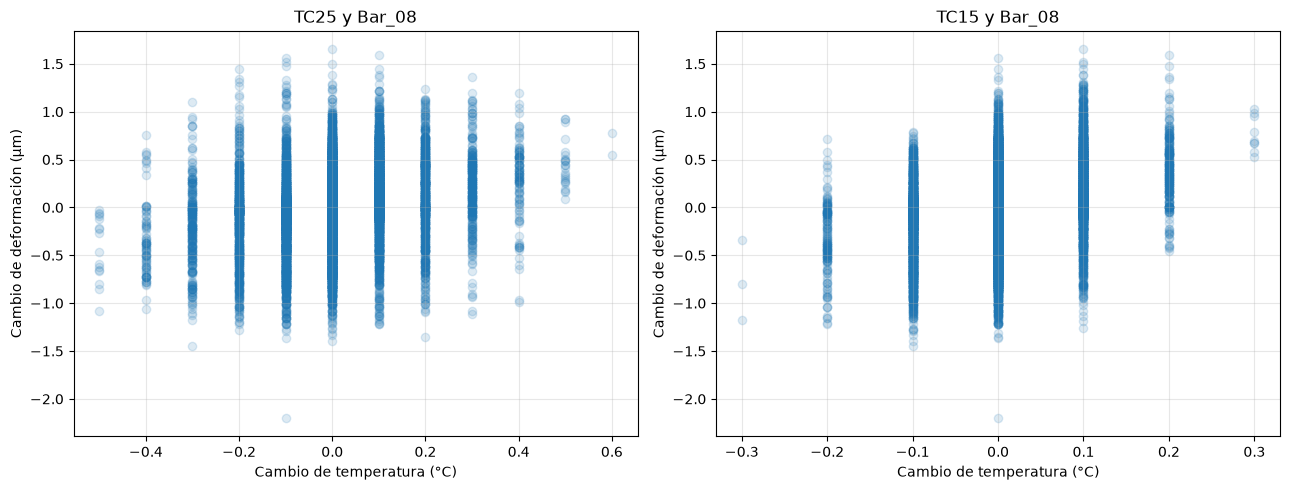

In [108]:
# Comparar cambios térmicos y estructurales en las parejas destacadas

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    cambios_termopares["Thermocouple_25"],
    cambios_ids["Bar_08"],
    alpha=0.15
)
axes[0].set_title("TC25 y Bar_08")
axes[0].set_xlabel("Cambio de temperatura (°C)")
axes[0].set_ylabel("Cambio de deformación (µm)")
axes[0].grid(alpha=0.3)

axes[1].scatter(
    cambios_termopares["Thermocouple_15"],
    cambios_ids["Bar_08"],
    alpha=0.15
)
axes[1].set_title("TC15 y Bar_08")
axes[1].set_xlabel("Cambio de temperatura (°C)")
axes[1].set_ylabel("Cambio de deformación (µm)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [109]:
# Calcular la temperatura media y la deformación media de cada instante

temperatura_media = subset_termopares.mean(axis=1)
deformacion_media = subset_ids.mean(axis=1)

# Calcular la correlación entre ambas variables

correlacion_global = temperatura_media.corr(deformacion_media)

print("Correlación global:", round(correlacion_global, 3))

Correlación global: -0.941


In [110]:
# Calcular el cambio medio de temperatura y deformación en cada instante

cambio_temperatura_medio = cambios_termopares.mean(axis=1)
cambio_deformacion_medio = cambios_ids.mean(axis=1)

# Calcular la correlación entre ambos cambios

correlacion_cambios_global = cambio_temperatura_medio.corr(
    cambio_deformacion_medio
)

print(
    "Correlación entre cambios medios:",
    round(correlacion_cambios_global, 3)
)

Correlación entre cambios medios: 0.05


### Conclusiones preliminares de H1: Relación entre temperatura y deformación térmica

El objetivo de este análisis es comprobar si el aumento de temperatura de los componentes del centro de mecanizado CNC está relacionado con la deformación térmica registrada por los sensores IDS.

Se han realizado tres comprobaciones:

**1. Correlación entre valores absolutos**

Se calculó la correlación entre la temperatura media de los 49 termopares y la deformación media de los 14 sensores IDS.

- Correlación obtenida: **-0,941**.
- Se observa una asociación lineal negativa muy fuerte entre ambas medias.

Sin embargo, esta correlación puede estar condicionada por la evolución temporal de las señales y no demuestra una relación física directa.

**2. Correlación entre cambios consecutivos**

Para evitar que las tendencias temporales dominen el resultado, se analizaron los cambios entre registros consecutivos, considerando únicamente intervalos de aproximadamente un segundo.

- Correlación obtenida: **+0,050**.
- La asociación lineal entre los cambios medios de temperatura y deformación es prácticamente inexistente.

**3. Análisis de parejas individuales**

Se estudiaron las parejas con mayor correlación entre cambios consecutivos:

- Thermocouple_25 – Bar_08: **+0,218**.
- Thermocouple_15 – Bar_08: **+0,206**.

Los diagramas de dispersión muestran una elevada dispersión de los puntos y no permiten identificar una tendencia lineal clara.

**Conclusión**

Los resultados obtenidos no permiten confirmar la hipótesis H1. La elevada correlación observada entre los valores absolutos desaparece al analizar los cambios consecutivos, lo que sugiere que la asociación inicial está condicionada por la evolución temporal de las señales.

No obstante, estos resultados no descartan posibles relaciones térmicas localizadas entre determinados termopares y sensores IDS. Será necesario estudiar individualmente los sensores de deformación para comprobar si existen comportamientos específicos que queden ocultos al calcular las medias globales.

In [111]:
# Calcular la correlación entre los cambios medios de temperatura
# y los cambios de cada sensor IDS

correlaciones_ids = cambios_ids.corrwith(
    cambio_temperatura_medio
)

# Ordenar las correlaciones de mayor a menor
correlaciones_ids = correlaciones_ids.sort_values(
    ascending=False
)

print(correlaciones_ids.round(3))

Bar_08    0.069
Bar_04    0.051
Bar_09    0.039
Bar_01    0.030
Bar_07    0.026
Bar_06    0.024
Bar_11    0.023
Bar_03    0.017
Bar_13   -0.002
Bar_10   -0.009
Bar_14   -0.011
Bar_12   -0.011
Bar_05   -0.013
Bar_02   -0.054
dtype: float64


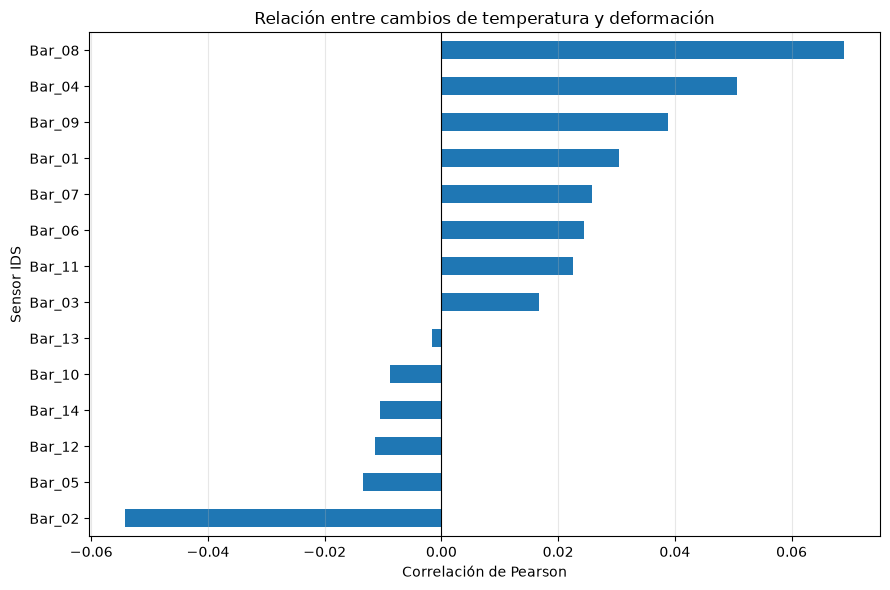

In [112]:
# Representar las correlaciones individuales de los IDS

correlaciones_ids.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Relación entre cambios de temperatura y deformación"
)

plt.xlabel("Correlación de Pearson")
plt.ylabel("Sensor IDS")
plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis individual de los sensores IDS

Para profundizar en la relación entre temperatura y deformación térmica, se ha estudiado cada uno de los 14 sensores IDS de forma independiente.

Se ha calculado la correlación de Pearson entre los cambios medios de temperatura de los 49 termopares y los cambios individuales de cada sensor IDS, considerando únicamente intervalos de adquisición próximos a un segundo.

**Resultados principales:**

- Bar_08 presenta la correlación positiva más elevada: **+0,069**.
- Bar_04 presenta una correlación de **+0,051**.
- Bar_09 presenta una correlación de **+0,039**.
- Bar_02 presenta la correlación negativa más elevada en valor absoluto: **−0,054**.
- Los demás sensores presentan correlaciones próximas a cero.

El gráfico de barras permite observar que todos los sensores presentan asociaciones lineales muy débiles con los cambios medios de temperatura.

**Conclusión del análisis:**

No se observa una relación lineal instantánea relevante entre los cambios medios de temperatura y la deformación individual registrada por los sensores IDS.

Este resultado no descarta posibles relaciones térmicas localizadas, ya que cada sensor podría responder de manera diferente a determinados componentes de la máquina.

### Estado de la hipótesis H1

La hipótesis H1 no queda confirmada con los análisis realizados hasta este punto.

Queda pendiente estudiar posibles relaciones con retraso temporal (*time lag*), ya que la deformación estructural podría manifestarse después de producirse el calentamiento.

También debe tenerse en cuenta que no se dispone de un plano de ubicación y orientación de los sensores IDS, lo que limita la interpretación física de sus mediciones.

In [113]:
# Preparar los cambios de temperatura y deformación

datos_retraso = pd.DataFrame({
    "Temperatura": cambios_termopares["Thermocouple_25"],
    "Deformacion": cambios_ids["Bar_08"],
    "Timestamp": sensores["Timestamp"]
})

# Identificar los tramos de adquisición continua
intervalos = datos_retraso["Timestamp"].diff()

datos_retraso["Grupo"] = (
    ~intervalos.between(0.9, 1.1)
).cumsum()

# Comprobar distintos retardos en minutos
resultados_retardos = {}

for minutos in [0, 1, 5, 10, 20, 30]:

    segundos = minutos * 60
    pares = []

    for _, grupo in datos_retraso.groupby("Grupo"):

        # Comparar el cambio de temperatura actual
        # con el cambio de deformación posterior
        deformacion_futura = grupo["Deformacion"].shift(-segundos)

        pareja = pd.concat(
            [grupo["Temperatura"], deformacion_futura],
            axis=1
        ).dropna()

        pares.append(pareja)

    datos_pareados = pd.concat(pares)

    resultados_retardos[minutos] = (
        datos_pareados.iloc[:, 0].corr(datos_pareados.iloc[:, 1])
    )

print("Correlación según el retraso temporal:")

for minutos, correlacion in resultados_retardos.items():
    print(f"{minutos:>2} minutos: {correlacion:.3f}")

Correlación según el retraso temporal:
 0 minutos: 0.218
 1 minutos: 0.013
 5 minutos: -0.035
10 minutos: -0.062
20 minutos: 0.012
30 minutos: -0.032


### Análisis de posibles retardos temporales (Time Lag)

Se ha investigado si la deformación registrada por el sensor Bar_08 presenta una respuesta retardada respecto a los cambios de temperatura del Thermocouple_25.

El objetivo es comprobar si el calentamiento de un componente puede manifestarse en la deformación estructural después de transcurrido cierto tiempo.

Para ello, se han comparado los cambios de temperatura con los cambios posteriores de deformación, evaluando diferentes intervalos temporales entre 0 y 30 minutos. Se han considerado únicamente registros pertenecientes a tramos de adquisición continua.

**Resultados obtenidos:**

| Retardo | Correlación |
|---|---:|
| 0 minutos | +0,218 |
| 1 minuto | +0,013 |
| 5 minutos | −0,035 |
| 10 minutos | −0,062 |
| 20 minutos | +0,012 |
| 30 minutos | −0,032 |

**Interpretación:**

La correlación positiva más elevada se obtiene cuando los cambios de temperatura y deformación se producen simultáneamente (+0,218).

Al introducir un retraso de un minuto, la correlación disminuye hasta +0,013 y permanece próxima a cero en los demás intervalos analizados.

**Conclusión:**

No se encuentra evidencia de una relación lineal retardada relevante entre Thermocouple_25 y Bar_08 en los intervalos estudiados.

Este resultado se limita a la pareja de sensores analizada y a retardos de hasta 30 minutos. No permite descartar otras relaciones entre termopares e IDS ni respuestas temporales más complejas.

In [114]:
# Analizar las variables operativas del husillo

resumen_husillo = subset_husillo[
    [
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity",
        "SPAxisLoad"
    ]
].describe().T

print(resumen_husillo.round(3))

                    count   mean    std      min    25%    50%    75%     max
SPActualSpeed   89655.000 -0.440  5.312 -100.000  0.000  0.000  0.000 100.000
SPAxisPower     89655.000  0.000  0.007   -0.140 -0.000  0.000  0.000   0.311
SPAxisIntensity 89655.000 48.759 32.567    0.000  0.000 70.492 70.501 151.561
SPAxisLoad      89655.000  0.034  0.141    0.000  0.008  0.009  0.010   8.678


In [115]:
# Calcular el porcentaje de registros con valor cero

porcentaje_ceros = (
    subset_husillo[
        [
            "SPActualSpeed",
            "SPAxisPower",
            "SPAxisIntensity",
            "SPAxisLoad"
        ]
    ].eq(0).mean() * 100
)

print("Porcentaje de valores iguales a cero:")
print(porcentaje_ceros.round(2))

Porcentaje de valores iguales a cero:
SPActualSpeed     94.780
SPAxisPower        0.000
SPAxisIntensity   30.840
SPAxisLoad         0.120
dtype: float64


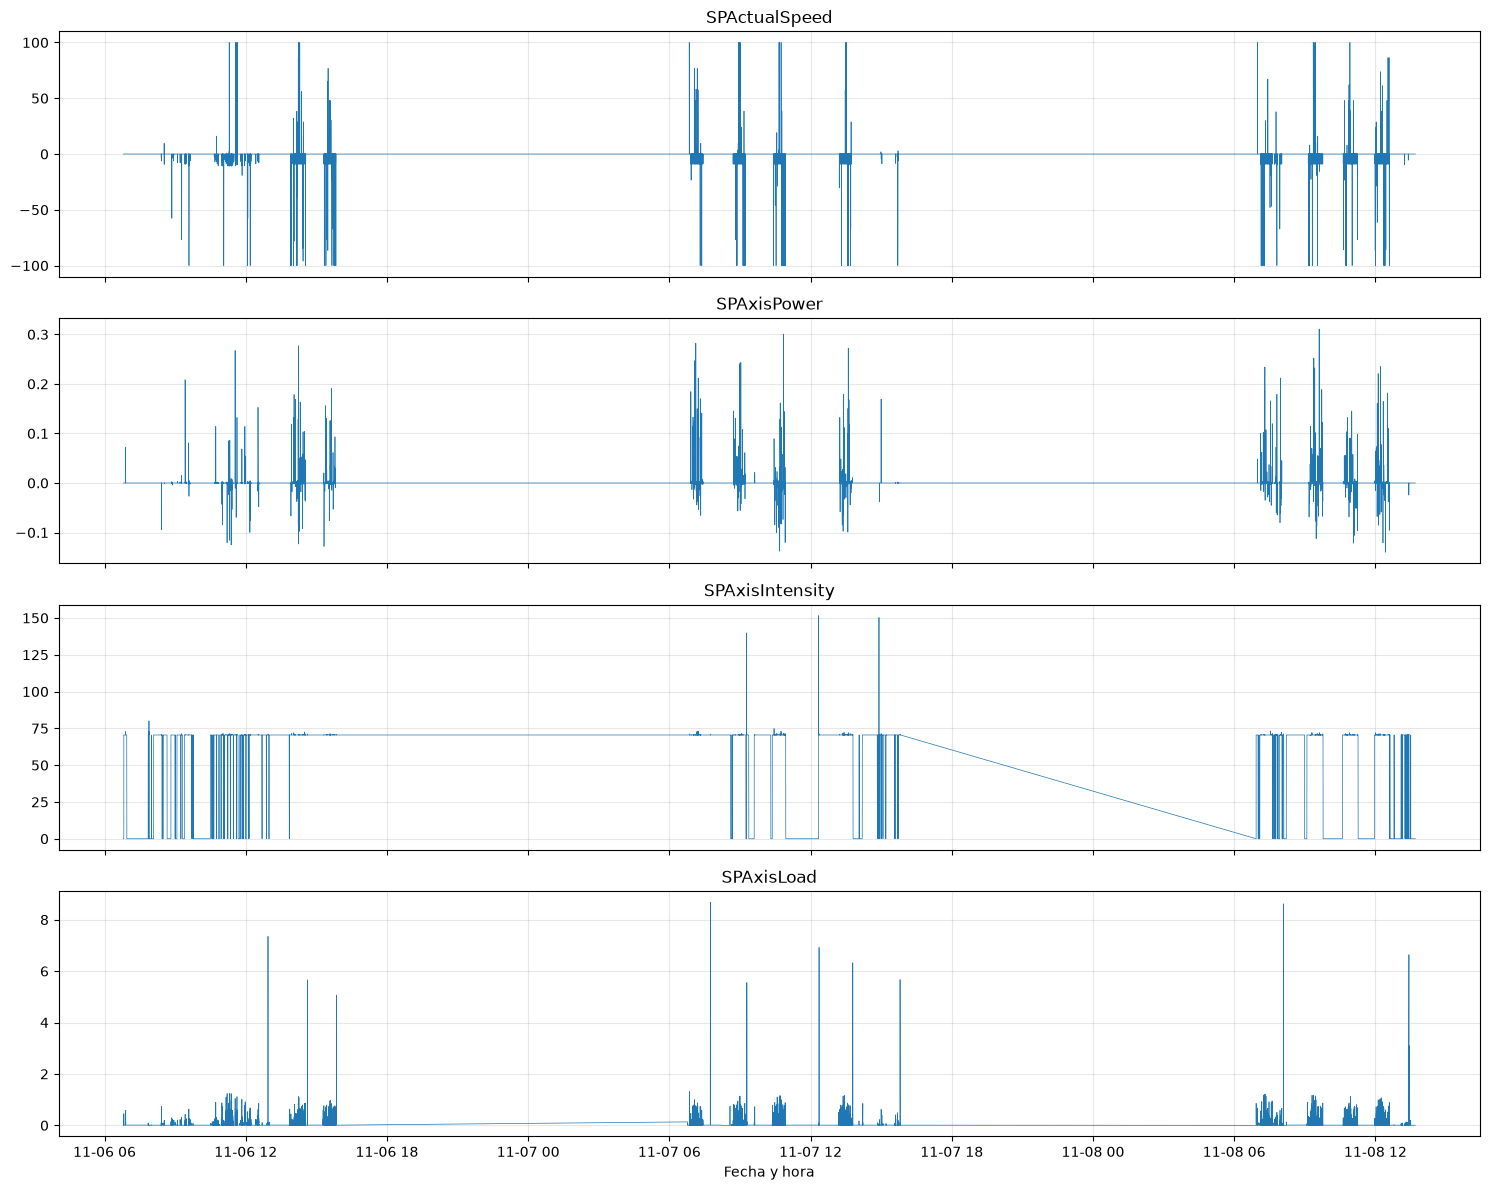

In [116]:
# Representar la evolución temporal de las variables del husillo

fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

variables_husillo = [
    "SPActualSpeed",
    "SPAxisPower",
    "SPAxisIntensity",
    "SPAxisLoad"
]

for ax, variable in zip(axes, variables_husillo):

    ax.plot(cnc["Date"], cnc[variable], linewidth=0.5)
    ax.set_title(variable)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Fecha y hora")

plt.tight_layout()
plt.show()

In [117]:
# Seleccionar los registros del 7 de noviembre entre las 13:00 y las 15:00

periodo_intensidad = cnc[
    (cnc["Date"] >= "2024-11-07 13:00:00") &
    (cnc["Date"] <= "2024-11-07 15:00:00")
][
    [
        "Date",
        "Timestamp",
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity",
        "SPAxisLoad"
    ]
]

print(periodo_intensidad.iloc[::600].round(3))

                         Date      Timestamp  SPActualSpeed  SPAxisPower  \
55107 2024-11-07 13:00:00.639 1730984400.639          0.000       -0.000   
55707 2024-11-07 13:10:00.673 1730985000.673          0.000       -0.000   
56307 2024-11-07 13:20:00.707 1730985600.707          0.000        0.000   
56907 2024-11-07 13:30:00.726 1730986200.726          0.000       -0.000   
57507 2024-11-07 13:40:00.760 1730986800.760          0.000       -0.000   
58107 2024-11-07 13:50:00.794 1730987400.794          0.000       -0.000   
58707 2024-11-07 14:00:00.827 1730988000.827          0.000       -0.000   
59307 2024-11-07 14:10:00.862 1730988600.862          0.000       -0.000   
59907 2024-11-07 14:20:00.899 1730989200.899          0.000        0.000   
60507 2024-11-07 14:30:00.899 1730989800.899          0.000        0.000   
61107 2024-11-07 14:40:00.933 1730990400.933          0.000       -0.000   
61707 2024-11-07 14:50:00.985 1730991000.985          0.000        0.000   

       SPAx

/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_2494/3496077704.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(periodo_intensidad.iloc[::600].round(3))


In [118]:
# Examinar los valores de intensidad más frecuentes

frecuencia_intensidad = (
    cnc["SPAxisIntensity"]
    .round(3)
    .value_counts()
    .head(15)
)

print(frecuencia_intensidad)

SPAxisIntensity
0.000     27653
70.498     2946
70.496     2876
70.495     2718
70.499     2683
70.500     2661
70.497     2634
70.501     2510
70.494     2510
70.493     2509
70.502     2400
70.503     2333
70.492     2164
70.491     2160
70.504     2071
Name: count, dtype: int64


In [119]:
# Identificar registros con intensidad próxima a 70,5 A

intensidad_alta = cnc["SPAxisIntensity"].between(70.4, 70.6)

# Comprobar las otras variables del husillo en esos registros

resumen_intensidad = cnc.loc[
    intensidad_alta,
    [
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisLoad"
    ]
].describe().T

print(resumen_intensidad.round(4))

                  count   mean   std      min    25%   50%   75%     max
SPActualSpeed 61658.000 -0.626 6.061 -100.000  0.000 0.000 0.000 100.000
SPAxisPower   61658.000  0.000 0.005   -0.138 -0.000 0.000 0.000   0.311
SPAxisLoad    61658.000  0.040 0.085    0.000  0.008 0.009 0.039   4.431


In [120]:
# Calcular el porcentaje de velocidad y potencia iguales a cero
# cuando la intensidad está alrededor de 70,5 A

registros_intensidad = cnc.loc[intensidad_alta]

print(
    "Velocidad igual a cero:",
    round((registros_intensidad["SPActualSpeed"] == 0).mean() * 100, 2),
    "%"
)

print(
    "Potencia igual a cero:",
    round((registros_intensidad["SPAxisPower"] == 0).mean() * 100, 2),
    "%"
)

Velocidad igual a cero: 92.47 %
Potencia igual a cero: 0.0 %


### Análisis de calidad de las señales del husillo

Durante la exploración de las variables operativas del husillo se han identificado comportamientos que requieren precaución antes de utilizarlas como indicadores de actividad.

**SPActualSpeed (velocidad):**
- El 94,78 % de los registros presenta valor cero.
- Los valores oscilan entre −100 y +100 rpm.
- Su distribución está muy concentrada en cero.

**SPAxisPower (potencia):**
- Presenta valores muy próximos a cero.
- Su rango oscila entre −0,140 y +0,311 kW.
- Aunque no hay valores exactamente iguales a cero, esto no implica que exista una potencia significativa.

**SPAxisIntensity (intensidad):**
- El 30,84 % de los registros presenta valor cero.
- Se observa una concentración muy elevada de valores alrededor de 70,5 A.
- Entre los registros con intensidad comprendida entre 70,4 y 70,6 A, el 92,47 % presenta velocidad igual a cero.

**SPAxisLoad (carga):**
- Presenta valores generalmente bajos.
- Su mediana es de 0,009 %.

**Conclusión:**

Las señales presentan comportamientos que dificultan su interpretación como indicadores directos de actividad del husillo. En particular, la intensidad muestra un nivel recurrente cercano a 70,5 A que no coincide habitualmente con valores de velocidad distintos de cero.

No se dispone de información suficiente para determinar si estos comportamientos responden a características del sistema de adquisición, valores de referencia o condiciones reales de funcionamiento.

Por tanto, antes de realizar el análisis de correlación de H2, será necesario identificar qué registros representan actividad efectiva del husillo y comprobar la coherencia entre sus variables operativas.

In [121]:
# Analizar los valores de velocidad distintos de cero

velocidad_activa = cnc.loc[
    cnc["SPActualSpeed"] != 0,
    "SPActualSpeed"
]

print(velocidad_activa.describe().round(3))

print("\nValores más frecuentes:")
print(velocidad_activa.value_counts().head(15))

count   4684.000
mean      -8.419
std       21.751
min     -100.000
25%       -8.828
50%       -8.828
75%       -7.059
max      100.000
Name: SPActualSpeed, dtype: float64

Valores más frecuentes:
SPActualSpeed
-8.828      1313
-8.828       720
-8.828       235
-8.828       150
-8.828       125
-100.000     123
-8.828       113
-10.594      106
-8.828        53
100.000       44
-2.648        42
-6.621        34
-8.828        32
-6.180        31
-1.488        29
Name: count, dtype: int64


In [122]:
# Examinar los valores únicos de velocidad con mayor precisión

frecuencia_velocidad = (
    velocidad_activa
    .round(6)
    .value_counts()
    .head(20)
)

print(frecuencia_velocidad.to_string())

SPActualSpeed
-8.828      2820
-100.000     123
-10.594      111
-6.621        60
-2.648        56
-6.180        49
-7.062        47
100.000       44
-5.297        38
-4.073        34
-0.883        33
-1.766        32
-8.387        31
-8.749        30
-1.488        29
-9.269        28
-4.414        28
-7.504        25
-7.945        25
-0.144        25


In [123]:
# Examinar la distribución de los valores positivos y negativos

print("Velocidades positivas:", (velocidad_activa > 0).sum())
print("Velocidades negativas:", (velocidad_activa < 0).sum())

print("\nPorcentaje de velocidades negativas:")
print(round((velocidad_activa < 0).mean() * 100, 2), "%")

Velocidades positivas: 188
Velocidades negativas: 4496

Porcentaje de velocidades negativas:
95.99 %


In [124]:
# Examinar los registros donde la velocidad es -8,828

registros_velocidad = cnc[
    np.isclose(cnc["SPActualSpeed"], -8.828, atol=0.0005)
][
    [
        "Date",
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity",
        "SPAxisLoad"
    ]
]

print(registros_velocidad.head(15).round(4))

                         Date  SPActualSpeed  SPAxisPower  SPAxisIntensity  \
6245  2024-11-06 08:31:52.668         -8.828        0.000           70.503   
6246  2024-11-06 08:31:53.668         -8.828       -0.000           70.487   
9418  2024-11-06 09:24:45.804         -8.828        0.001           70.484   
9419  2024-11-06 09:24:46.804         -8.828        0.001           70.484   
9420  2024-11-06 09:24:47.804         -8.828       -0.000           70.516   
9424  2024-11-06 09:24:51.804         -8.828        0.001           70.515   
9425  2024-11-06 09:24:52.804         -8.828        0.001           70.515   
9596  2024-11-06 09:27:43.836         -8.828        0.002           70.502   
9597  2024-11-06 09:27:44.836         -8.828       -0.000           70.502   
14350 2024-11-06 10:46:58.077         -8.828       -0.000           70.502   
14351 2024-11-06 10:46:59.077         -8.828       -0.000           70.502   
14356 2024-11-06 10:47:04.077         -8.828        0.002       

/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_2494/2049523006.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(registros_velocidad.head(15).round(4))


In [128]:
# Identificar los registros con velocidad -8,828 rpm

mascara_velocidad = pd.Series(
    np.isclose(cnc["SPActualSpeed"], -8.828, atol=0.0005),
    index=cnc.index
)

# Identificar dónde comienza o termina cada bloque

cambios_estado = (
    mascara_velocidad.ne(mascara_velocidad.shift())
    .cumsum()
)

# Calcular la duración de cada bloque consecutivo

duracion_bloques = (
    mascara_velocidad[mascara_velocidad]
    .groupby(cambios_estado[mascara_velocidad])
    .size()
)

# Mostrar resultados

print("Número de bloques:", len(duracion_bloques))
print("\nDuración de los bloques (segundos):")
print(duracion_bloques.describe())

Número de bloques: 1396

Duración de los bloques (segundos):
count   1396.000
mean       2.020
std        0.666
min        1.000
25%        2.000
50%        2.000
75%        2.000
max        6.000
dtype: float64


In [129]:
# Examinar los valores más frecuentes de carga del husillo

frecuencia_carga = (
    cnc["SPAxisLoad"]
    .round(4)
    .value_counts()
    .head(15)
)

print(frecuencia_carga.to_string())

SPAxisLoad
0.009    7615
0.009    5727
0.009    5226
0.009    4370
0.008    3643
0.009    3534
0.008    3518
0.009    3154
0.008    2872
0.010    1859
0.002    1363
0.009    1345
0.007    1338
0.006    1287
0.006    1195


In [130]:
# Analizar los registros donde la carga supera el 1 %

carga_activa = cnc.loc[
    cnc["SPAxisLoad"] > 1,
    [
        "SPActualSpeed",
        "SPAxisPower",
        "SPAxisIntensity",
        "SPAxisLoad"
    ]
]

print(carga_activa.describe().round(3))

       SPActualSpeed  SPAxisPower  SPAxisIntensity  SPAxisLoad
count        103.000      103.000          103.000     103.000
mean           8.299        0.018           70.718       3.032
std           26.899        0.086            0.222       2.166
min            0.000       -0.138           70.348       1.002
25%            0.000       -0.000           70.514       1.128
50%            0.000        0.000           70.706       2.137
75%            0.000        0.000           70.840       4.936
max          100.000        0.277           71.257       8.678


In [131]:
# Calcular la temperatura media de los termopares en cada registro

temperatura_media = subset_termopares.mean(axis=1)

# Separar los registros según la carga del husillo

temperatura_carga_baja = temperatura_media[cnc["SPAxisLoad"] <= 1]
temperatura_carga_alta = temperatura_media[cnc["SPAxisLoad"] > 1]

# Comparar ambos grupos

print("Carga <= 1 %")
print(temperatura_carga_baja.describe().round(3))

print("\nCarga > 1 %")
print(temperatura_carga_alta.describe().round(3))

Carga <= 1 %
count   89290.000
mean       21.049
std         1.333
min        17.606
25%        19.672
50%        21.743
75%        22.157
max        23.108
dtype: float64

Carga > 1 %
count   103.000
mean     20.784
std       1.333
min      18.043
25%      19.651
50%      20.898
75%      21.971
max      22.573
dtype: float64


### Exploración de las variables operativas del husillo

Se han analizado las cuatro variables disponibles para estudiar la actividad del husillo: velocidad, potencia, intensidad y carga.

Durante el análisis se han identificado varios comportamientos que dificultan su interpretación física:

- **SPActualSpeed:** el 94,78 % de los registros presenta valores iguales a cero. Los valores restantes se concentran principalmente en valores negativos, destacando −8,828, que aparece en episodios muy cortos.
- **SPAxisPower:** presenta valores extremadamente próximos a cero, con un rango entre −0,140 y 0,311 kW.
- **SPAxisIntensity:** presenta una concentración de valores alrededor de 70,5 A. En el 92,47 % de los registros con intensidad próxima a ese valor, la velocidad es cero.
- **SPAxisLoad:** presenta valores generalmente bajos. Únicamente 103 registros superan el 1 % de carga.

También se comparó la temperatura media de los 49 termopares según el nivel de carga del husillo:

- Carga igual o inferior al 1 %: temperatura media de 21,049 °C.
- Carga superior al 1 %: temperatura media de 20,784 °C.

La diferencia observada es de −0,265 °C para el grupo de mayor carga.

**Conclusión preliminar de H2:**

Los datos disponibles no permiten establecer una relación fiable entre la actividad del husillo y el incremento de temperatura de la máquina. Las señales operativas presentan distribuciones y comportamientos que requieren aclaración antes de utilizarlas como indicadores directos de actividad.

No se confirma ni se rechaza definitivamente H2. Para continuar será necesario disponer de una interpretación más precisa de las señales del husillo o de documentación adicional sobre su adquisición.

In [132]:
# Seleccionar las temperaturas de los ejes disponibles

temperaturas_ejes = cnc[
    [
        "XAxisTemperature",
        "YAxisTemperature",
        "ZAxisTemperature",
        "CAxisTemperature"
    ]
]

# Obtener estadísticas descriptivas

resumen_temperaturas_ejes = temperaturas_ejes.describe().T

print(resumen_temperaturas_ejes.round(3))

                     count   mean    std    min    25%    50%    75%    max
XAxisTemperature 89655.000 34.743 11.097 20.500 23.300 33.949 43.010 61.100
YAxisTemperature 89655.000 32.536 10.882 19.300 23.900 29.500 37.400 64.500
ZAxisTemperature 89655.000 31.234  7.908 19.514 24.098 30.300 35.400 53.300
CAxisTemperature 89655.000 20.120  1.210 17.602 19.099 20.210 21.217 23.100


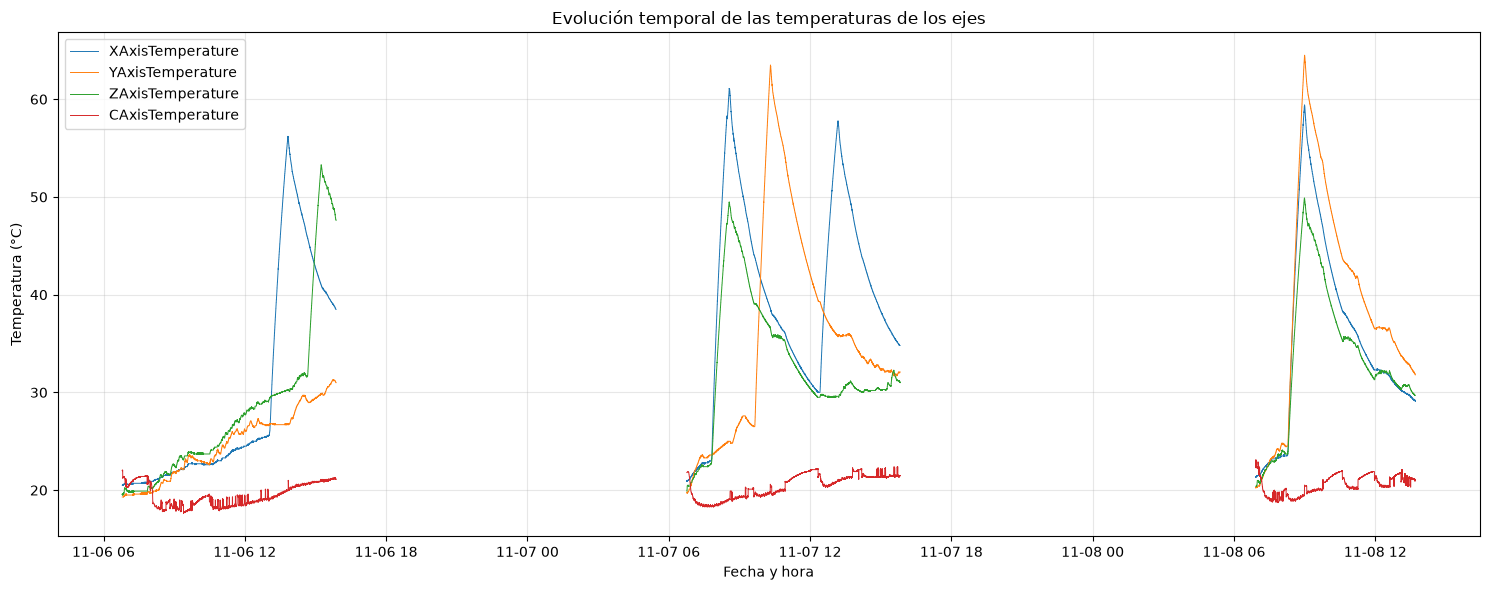

In [133]:
# Calcular los intervalos entre registros

intervalos_cnc = cnc["Timestamp"].diff()

# Preparar las temperaturas para representar su evolución temporal

temperaturas_ejes_grafico = temperaturas_ejes.copy()

# Evitar unir gráficamente periodos separados por interrupciones
temperaturas_ejes_grafico.loc[
    ~intervalos_cnc.between(0.9, 1.1)
] = np.nan

# Representar la evolución temporal

plt.figure(figsize=(15, 6))

for columna in temperaturas_ejes_grafico.columns:
    plt.plot(
        cnc["Date"],
        temperaturas_ejes_grafico[columna],
        label=columna,
        linewidth=0.7
    )

plt.title("Evolución temporal de las temperaturas de los ejes")
plt.xlabel("Fecha y hora")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Evolución temporal de las temperaturas de los ejes

Se ha representado la evolución temporal de las temperaturas registradas por el controlador CNC en los ejes X, Y, Z y C durante los tres días de ensayos.

Para evitar representar como continuos los periodos sin adquisición de datos, se han separado los intervalos mediante valores nulos en las interrupciones temporales.

**Observaciones principales:**

- **Eje X:** presenta episodios de calentamiento intenso durante las tres jornadas, alcanzando temperaturas próximas a 60 °C.
- **Eje Y:** registra los máximos térmicos más elevados, con un máximo de 64,5 °C.
- **Eje Z:** muestra ciclos de calentamiento y enfriamiento, con temperaturas máximas próximas a 50-53 °C.
- **Eje C:** mantiene temperaturas considerablemente más estables, generalmente entre 18 y 23 °C.

**Conclusión:**

Las temperaturas de los ejes presentan comportamientos diferenciados y ciclos de calentamiento y enfriamiento durante los ensayos.

Los ejes X, Y y Z muestran una variabilidad térmica considerablemente superior a la del eje C. Estos resultados indican que la evolución térmica de la máquina no es uniforme.

Este análisis aporta evidencia descriptiva para H4, aunque todavía es necesario relacionar las temperaturas con las condiciones de funcionamiento del CNC para evaluar la hipótesis.

In [134]:
# Comparar las temperaturas de los ejes según el modo del controlador

temperaturas_por_modo = cnc.groupby("ControllerMode")[
    [
        "XAxisTemperature",
        "YAxisTemperature",
        "ZAxisTemperature",
        "CAxisTemperature"
    ]
].agg(["count", "mean", "std"])

print(temperaturas_por_modo.round(3))

               XAxisTemperature               YAxisTemperature                \
                          count   mean    std            count   mean    std   
ControllerMode                                                                 
0                         25083 29.864 10.924            25083 27.110  8.081   
1                           397 31.013  8.667              397 28.476  4.845   
2                         64175 36.673 10.575            64175 34.683 11.115   

               ZAxisTemperature              CAxisTemperature               
                          count   mean   std            count   mean   std  
ControllerMode                                                              
0                         25083 27.485 7.337            25083 20.288 1.254  
1                           397 27.142 4.126              397 20.324 1.055  
2                         64175 32.724 7.642            64175 20.053 1.187  


### Relación entre ControllerMode y las temperaturas de los ejes

Se ha analizado la temperatura media de los ejes X, Y, Z y C agrupando los registros según los valores de `ControllerMode`.

**Resultados principales:**

- El código 0 presenta temperaturas medias de 29,864 °C en X, 27,110 °C en Y y 27,485 °C en Z.
- El código 1 presenta temperaturas medias de 31,013 °C en X, 28,476 °C en Y y 27,142 °C en Z.
- El código 2 presenta las temperaturas medias más elevadas en X, Y y Z: 36,673 °C, 34,683 °C y 32,724 °C, respectivamente.
- El eje C presenta temperaturas medias similares en los tres códigos, alrededor de 20 °C.

La diferencia entre los códigos 0 y 2 alcanza 6,809 °C en X, 7,573 °C en Y y 5,239 °C en Z.

**Conclusión:**

Se observan diferencias térmicas entre los distintos valores de `ControllerMode`, especialmente en los ejes X, Y y Z. Esto sugiere una posible asociación entre el modo del controlador y el comportamiento térmico de la máquina.

No obstante, los códigos todavía no están identificados semánticamente y las diferencias observadas no demuestran causalidad.

In [135]:
# Comparar las temperaturas de los ejes según el estado de ejecución

temperaturas_por_estado = cnc.groupby("ExecutionState")[
    [
        "XAxisTemperature",
        "YAxisTemperature",
        "ZAxisTemperature",
        "CAxisTemperature"
    ]
].agg(["count", "mean", "std"])

print(temperaturas_por_estado.round(3))

               XAxisTemperature               YAxisTemperature                \
                          count   mean    std            count   mean    std   
ExecutionState                                                                 
1                          2575 23.649  3.684             2575 23.614  2.288   
2                          4750 29.881  7.960             4750 28.771  5.902   
3                         45080 38.342 11.304            45080 33.600 11.254   
5                         37250 31.775  9.836            37250 32.346 10.873   

               ZAxisTemperature              CAxisTemperature               
                          count   mean   std            count   mean   std  
ExecutionState                                                              
1                          2575 24.171 1.627             2575 19.210 0.839  
2                          4750 27.817 3.941             4750 20.156 1.285  
3                         45080 33.436 8.357          

### Relación entre ExecutionState y las temperaturas de los ejes

Se ha estudiado la temperatura media de los ejes X, Y, Z y C agrupando los registros según los valores de `ExecutionState`.

**Resultados principales:**

- El estado 1 presenta las temperaturas medias más bajas en X, Y y Z.
- El estado 2 muestra temperaturas intermedias.
- El estado 3 presenta las temperaturas medias más elevadas en los ejes X, Y y Z.
- El estado 5 presenta temperaturas inferiores al estado 3 en los ejes X y Z, mientras que en Y mantiene valores relativamente próximos.
- El eje C presenta variaciones térmicas mucho menores entre los distintos estados.

La diferencia de temperatura media entre los estados 1 y 3 alcanza 14,693 °C en X, 9,986 °C en Y y 9,265 °C en Z.

**Conclusión:**

Se observan diferencias térmicas importantes entre los distintos valores de `ExecutionState`, especialmente en los ejes X, Y y Z. Estos resultados sugieren una asociación entre el estado de ejecución del CNC y la evolución térmica de la máquina.

Sin embargo, los códigos de estado todavía no están identificados semánticamente. Por tanto, no es posible atribuir las diferencias observadas a operaciones concretas del CNC ni establecer una relación causal.



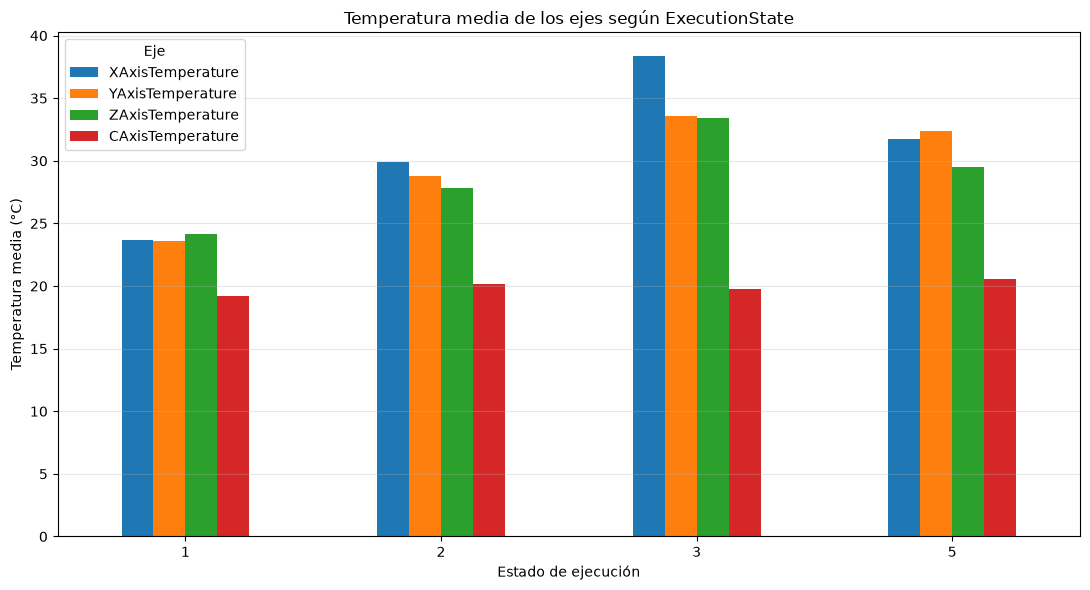

In [136]:
# Calcular las temperaturas medias por estado de ejecución

temperaturas_estado_grafico = cnc.groupby("ExecutionState")[
    [
        "XAxisTemperature",
        "YAxisTemperature",
        "ZAxisTemperature",
        "CAxisTemperature"
    ]
].mean()

# Representar las temperaturas medias

temperaturas_estado_grafico.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Temperatura media de los ejes según ExecutionState")
plt.xlabel("Estado de ejecución")
plt.ylabel("Temperatura media (°C)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Eje")
plt.tight_layout()
plt.show()

### Comparación visual de temperaturas según ExecutionState

Se ha representado la temperatura media de los ejes X, Y, Z y C para cada uno de los cuatro valores registrados en `ExecutionState`.

El gráfico permite identificar las siguientes diferencias:

- El estado 1 presenta las temperaturas medias más bajas en los ejes X, Y y Z.
- El estado 2 muestra un incremento térmico respecto al estado 1.
- El estado 3 registra las temperaturas medias más elevadas, especialmente en el eje X.
- El estado 5 presenta temperaturas inferiores al estado 3 en X y Z, pero superiores a las del estado 1.
- El eje C mantiene temperaturas relativamente estables en todos los estados.

**Conclusión:**

La representación gráfica confirma las diferencias térmicas observadas en el análisis estadístico descriptivo. Los ejes X, Y y Z presentan temperaturas medias claramente diferenciadas según el valor de `ExecutionState`, mientras que el eje C muestra una variación mucho menor.

Estos resultados aportan evidencia descriptiva favorable a H4. Sin embargo, todavía es necesario comprobar si las diferencias se mantienen al considerar la evolución temporal de los ensayos y la distribución de los estados entre jornadas.



In [137]:
# Contar los registros de cada estado de ejecución por jornada

distribucion_estados = pd.crosstab(
    cnc["Date"].dt.date,
    cnc["ExecutionState"]
)

print(distribucion_estados)

ExecutionState     1     2      3      5
Date                                    
2024-11-06      2408  2147  15504  12620
2024-11-07       167  1430  17398  13586
2024-11-08         0  1173  12178  11044


### Distribución de ExecutionState por jornada

Se ha analizado la frecuencia de los diferentes valores de `ExecutionState` durante los tres días de ensayos.

Para facilitar la comparación, se han calculado los porcentajes de cada estado respecto al total de registros de cada jornada.

**Observaciones principales:**

- El estado 3 es el más frecuente durante los tres días, representando aproximadamente entre el 47 % y el 53 % de los registros.
- El estado 5 aumenta progresivamente su presencia, desde el 38,62 % el primer día hasta el 45,27 % el tercero.
- El estado 1 disminuye considerablemente su presencia y desaparece el 8 de noviembre.
- El estado 2 mantiene una proporción relativamente estable.

**Conclusión:**

La distribución de los estados de ejecución no es idéntica entre las jornadas. Esta diferencia temporal puede influir en las temperaturas medias calculadas anteriormente.

Por tanto, es necesario considerar el día del ensayo al estudiar la relación entre `ExecutionState` y las temperaturas de los ejes, evitando atribuir todas las diferencias térmicas exclusivamente al estado de ejecución.

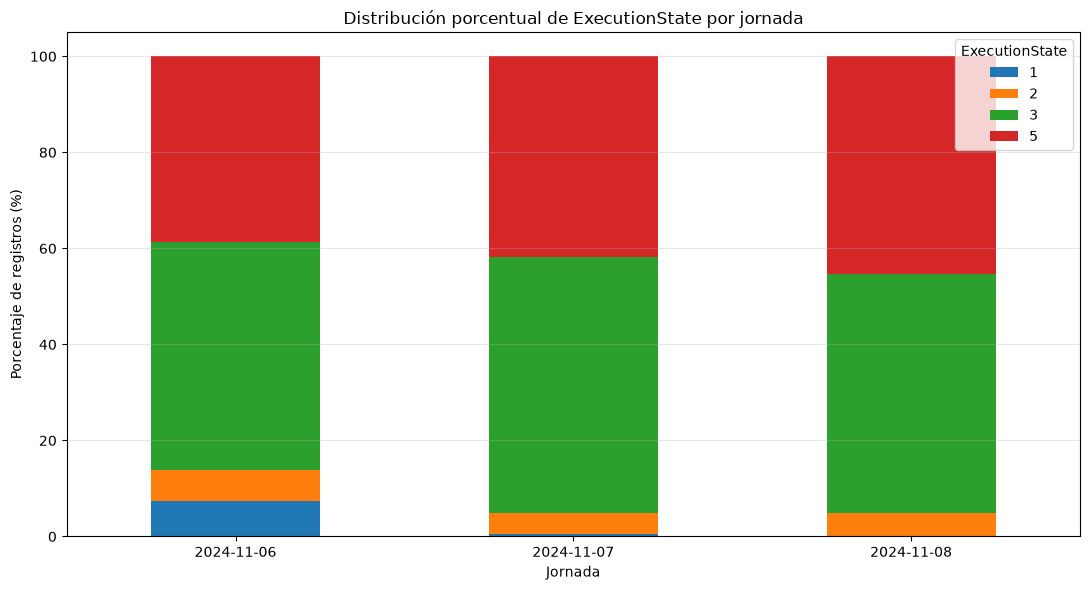

In [138]:
# Calcular el porcentaje de cada estado dentro de cada jornada

distribucion_porcentual = pd.crosstab(
    cnc["Date"].dt.date,
    cnc["ExecutionState"],
    normalize="index"
) * 100

# Representar la distribución porcentual

distribucion_porcentual.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Distribución porcentual de ExecutionState por jornada")
plt.xlabel("Jornada")
plt.ylabel("Porcentaje de registros (%)")
plt.xticks(rotation=0)
plt.legend(title="ExecutionState")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [139]:
temperatura_x_jornada_estado = cnc.pivot_table(
    index=cnc["Date"].dt.date,
    columns="ExecutionState",
    values="XAxisTemperature",
    aggfunc="mean"
)

print(temperatura_x_jornada_estado.round(3))

ExecutionState      1      2      3      5
Date                                      
2024-11-06     22.680 23.213 35.532 24.208
2024-11-07     37.618 39.894 41.952 36.731
2024-11-08        NaN 29.876 36.761 34.324


### Comparación de temperatura del eje X según jornada y ExecutionState

Para controlar parcialmente las diferencias entre jornadas, se ha calculado la temperatura media del eje X agrupando los registros simultáneamente por fecha y estado de ejecución.

**Resultados principales:**

- El estado 3 presenta la temperatura media más elevada en las tres jornadas analizadas.
- El 6 de noviembre alcanza 35,532 °C en el estado 3, frente a valores próximos a 23 °C en los estados 1 y 2.
- El 7 de noviembre, el estado 3 registra una media de 41,952 °C.
- El 8 de noviembre, el estado 3 alcanza 36,761 °C.

También se observan diferencias térmicas importantes entre jornadas para un mismo estado de ejecución.

**Conclusión:**

El estado 3 mantiene una asociación con temperaturas medias más elevadas del eje X incluso al comparar los registros dentro de cada jornada. Esto refuerza la evidencia descriptiva de una relación entre las condiciones de ejecución y el comportamiento térmico.

No obstante, también existe una variación importante entre jornadas. Por tanto, el estado de ejecución no explica por sí solo las diferencias de temperatura.

In [140]:
# Comparar temperaturas de los ejes X, Y y Z
# según jornada y estado de ejecución

temperaturas_por_jornada_estado = cnc.pivot_table(
    index=cnc["Date"].dt.date,
    columns="ExecutionState",
    values=[
        "XAxisTemperature",
        "YAxisTemperature",
        "ZAxisTemperature"
    ],
    aggfunc="mean"
)

print(temperaturas_por_jornada_estado.round(3))

               XAxisTemperature                      YAxisTemperature         \
ExecutionState                1      2      3      5                1      2   
Date                                                                           
2024-11-06               22.680 23.213 35.532 24.208           23.015 23.943   
2024-11-07               37.618 39.894 41.952 36.731           32.248 32.837   
2024-11-08                  NaN 29.876 36.761 34.324              NaN 32.651   

                             ZAxisTemperature                       
ExecutionState      3      5                1      2      3      5  
Date                                                                
2024-11-06     26.774 22.646           23.746 24.935 32.567 24.124  
2024-11-07     35.095 36.419           30.294 30.546 33.719 31.787  
2024-11-08     40.156 38.419              NaN 29.767 34.139 32.804  


### Comparación térmica de los ejes X, Y y Z según jornada y ExecutionState

Se ha ampliado el análisis anterior para estudiar conjuntamente las temperaturas de los ejes X, Y y Z según la jornada y el estado de ejecución del CNC.

**Resultados principales:**

- **Eje X:** el estado 3 presenta la temperatura media más elevada durante las tres jornadas, alcanzando 35,532 °C, 41,952 °C y 36,761 °C, respectivamente.
- **Eje Y:** también presenta las temperaturas más elevadas en el estado 3 durante los tres días, con medias de 26,774 °C, 35,095 °C y 40,156 °C.
- **Eje Z:** mantiene el mismo patrón, con temperaturas medias de 32,567 °C, 33,719 °C y 34,139 °C en el estado 3.

**Conclusión:**

El estado de ejecución 3 presenta una asociación consistente con temperaturas medias más elevadas en los tres ejes lineales, incluso al comparar los registros dentro de cada jornada.

Este resultado aporta evidencia descriptiva favorable a H4. No obstante, las diferencias entre jornadas y la falta de identificación semántica de los códigos impiden establecer una relación causal o atribuir el calentamiento a una operación concreta del CNC.

In [141]:
# Analizar la distribución conjunta de los estados del CNC

distribucion_modos_estados = pd.crosstab(
    cnc["ControllerMode"],
    cnc["ExecutionState"]
)

print(distribucion_modos_estados)

ExecutionState     1     2      3      5
ControllerMode                          
0               2406  1162   1070  20445
1                  0     2      4    391
2                169  3586  44006  16414


### Relación entre ControllerMode y ExecutionState

Se ha analizado la distribución conjunta de los valores de `ControllerMode` y `ExecutionState` mediante una tabla de contingencia.

**Resultados principales:**

- El modo 0 concentra principalmente registros del estado 5.
- El modo 1 presenta un 98,49 % de registros correspondientes al estado 5, aunque su tamaño muestral es reducido (397 registros).
- El modo 2 concentra principalmente registros del estado 3, que representa aproximadamente el 68,57 % de sus observaciones.
- El 97,62 % de todos los registros correspondientes al estado 3 pertenece al modo 2.

**Conclusión:**

Existe una asociación importante entre `ControllerMode` y `ExecutionState`. Por tanto, las diferencias térmicas observadas al estudiar estas variables por separado podrían estar parcialmente relacionadas con la distribución conjunta de ambos códigos.

Para evitar atribuir dos veces el mismo comportamiento, será necesario analizar conjuntamente las condiciones del controlador y las temperaturas de los ejes.

Los códigos todavía no disponen de una interpretación semántica confirmada, por lo que no se asignan nombres operativos a sus valores.

In [142]:
# Calcular el porcentaje de cada estado dentro de cada modo

distribucion_porcentual_modos = pd.crosstab(
    cnc["ControllerMode"],
    cnc["ExecutionState"],
    normalize="index"
) * 100

print(distribucion_porcentual_modos.round(2))

ExecutionState     1     2      3      5
ControllerMode                          
0              9.590 4.630  4.270 81.510
1              0.000 0.500  1.010 98.490
2              0.260 5.590 68.570 25.580


### Distribución porcentual conjunta de ControllerMode y ExecutionState

Se ha calculado la distribución porcentual de los estados de ejecución dentro de cada modo del controlador.

**Resultados principales:**

- En `ControllerMode = 0`, el estado 5 representa el 81,51 % de los registros.
- En `ControllerMode = 1`, el estado 5 representa el 98,49 %.
- En `ControllerMode = 2`, predomina el estado 3, con un 68,57 %.

Estos resultados muestran una asociación importante entre ambas variables.

**Conclusión:**

Los modos del controlador y los estados de ejecución presentan distribuciones relacionadas. Por tanto, sus asociaciones con la temperatura deben interpretarse conjuntamente y no como dos efectos independientes.

Todavía no se conoce el significado operativo exacto de los códigos, por lo que no se atribuyen nombres a los distintos estados.

In [143]:
# Comparar la temperatura del eje X según modo y estado de ejecución

temperatura_x_modo_estado = cnc.pivot_table(
    index="ControllerMode",
    columns="ExecutionState",
    values="XAxisTemperature",
    aggfunc="mean"
)

print(temperatura_x_modo_estado.round(3))

ExecutionState      1      2      3      5
ControllerMode                            
0              22.680 29.410 37.465 30.338
1                 NaN 43.900 31.500 30.942
2              37.445 30.025 38.363 33.584


In [144]:
# Contar los registros de cada combinación de modo y estado

conteo_modo_estado = pd.crosstab(
    cnc["ControllerMode"],
    cnc["ExecutionState"]
)

print(conteo_modo_estado)

ExecutionState     1     2      3      5
ControllerMode                          
0               2406  1162   1070  20445
1                  0     2      4    391
2                169  3586  44006  16414


In [145]:
# Comparar temperatura de los ejes según modo, estado y día

temperatura_modo_estado_dia = cnc.pivot_table(
    index=["Date"],
    columns=["ControllerMode", "ExecutionState"],
    values=["XAxisTemperature", "YAxisTemperature", "ZAxisTemperature"],
    aggfunc="mean"
)

print(temperatura_modo_estado_dia.round(2))

                        XAxisTemperature                                    \
ControllerMode                         0                     1           2   
ExecutionState                         1      2   3      5   2   3   5   1   
Date                                                                         
2024-11-06 06:47:47.362              NaN    NaN NaN 20.500 NaN NaN NaN NaN   
2024-11-06 06:47:48.362              NaN    NaN NaN 20.500 NaN NaN NaN NaN   
2024-11-06 06:47:49.363              NaN    NaN NaN 20.500 NaN NaN NaN NaN   
2024-11-06 06:47:50.362              NaN    NaN NaN 20.500 NaN NaN NaN NaN   
2024-11-06 06:47:51.362              NaN    NaN NaN 20.500 NaN NaN NaN NaN   
...                                  ...    ...  ..    ...  ..  ..  ..  ..   
2024-11-08 13:41:54.388              NaN 29.100 NaN    NaN NaN NaN NaN NaN   
2024-11-08 13:41:55.388              NaN 29.100 NaN    NaN NaN NaN NaN NaN   
2024-11-08 13:41:56.388              NaN 29.100 NaN    NaN NaN N

In [146]:
# Extraer el día de cada registro
cnc["Day"] = cnc["Date"].dt.date

# Calcular temperaturas medias por día, modo y estado
temperatura_modo_estado_dia = cnc.pivot_table(
    index="Day",
    columns=["ControllerMode", "ExecutionState"],
    values=[
        "XAxisTemperature",
        "YAxisTemperature",
        "ZAxisTemperature"
    ],
    aggfunc="mean"
)

print(temperatura_modo_estado_dia.round(2))

               XAxisTemperature                                            \
ControllerMode                0                           1                 
ExecutionState                1      2      3      5      2      3      5   
Day                                                                         
2024-11-06               22.680 21.880 36.410 22.960    NaN    NaN 34.570   
2024-11-07                  NaN 42.500 40.390 43.580 43.900 39.500 36.270   
2024-11-08                  NaN 30.140 30.690 30.380    NaN 23.500 25.610   

                                           YAxisTemperature                \
ControllerMode      2                                     0                 
ExecutionState      1      2      3      5                1      2      3   
Day                                                                         
2024-11-06     23.010 23.340 35.520 28.620           23.010 21.480 26.580   
2024-11-07     37.620 39.780 42.010 32.000              NaN 29.220 33.250  

In [147]:
# Contar registros por día, modo y estado

conteo_modo_estado_dia = pd.crosstab(
    index=cnc["Day"],
    columns=[
        cnc["ControllerMode"],
        cnc["ExecutionState"]
    ]
)

print(conteo_modo_estado_dia)

ControllerMode     0                  1            2                   
ExecutionState     1    2    3     5  2  3    5    1     2      3     5
Day                                                                    
2024-11-06      2406  187  255  9879  0  0   40    2  1960  15249  2701
2024-11-07         0   56  597  5487  2  2  162  167  1372  16799  7937
2024-11-08         0  919  218  5079  0  2  189    0   254  11958  5776


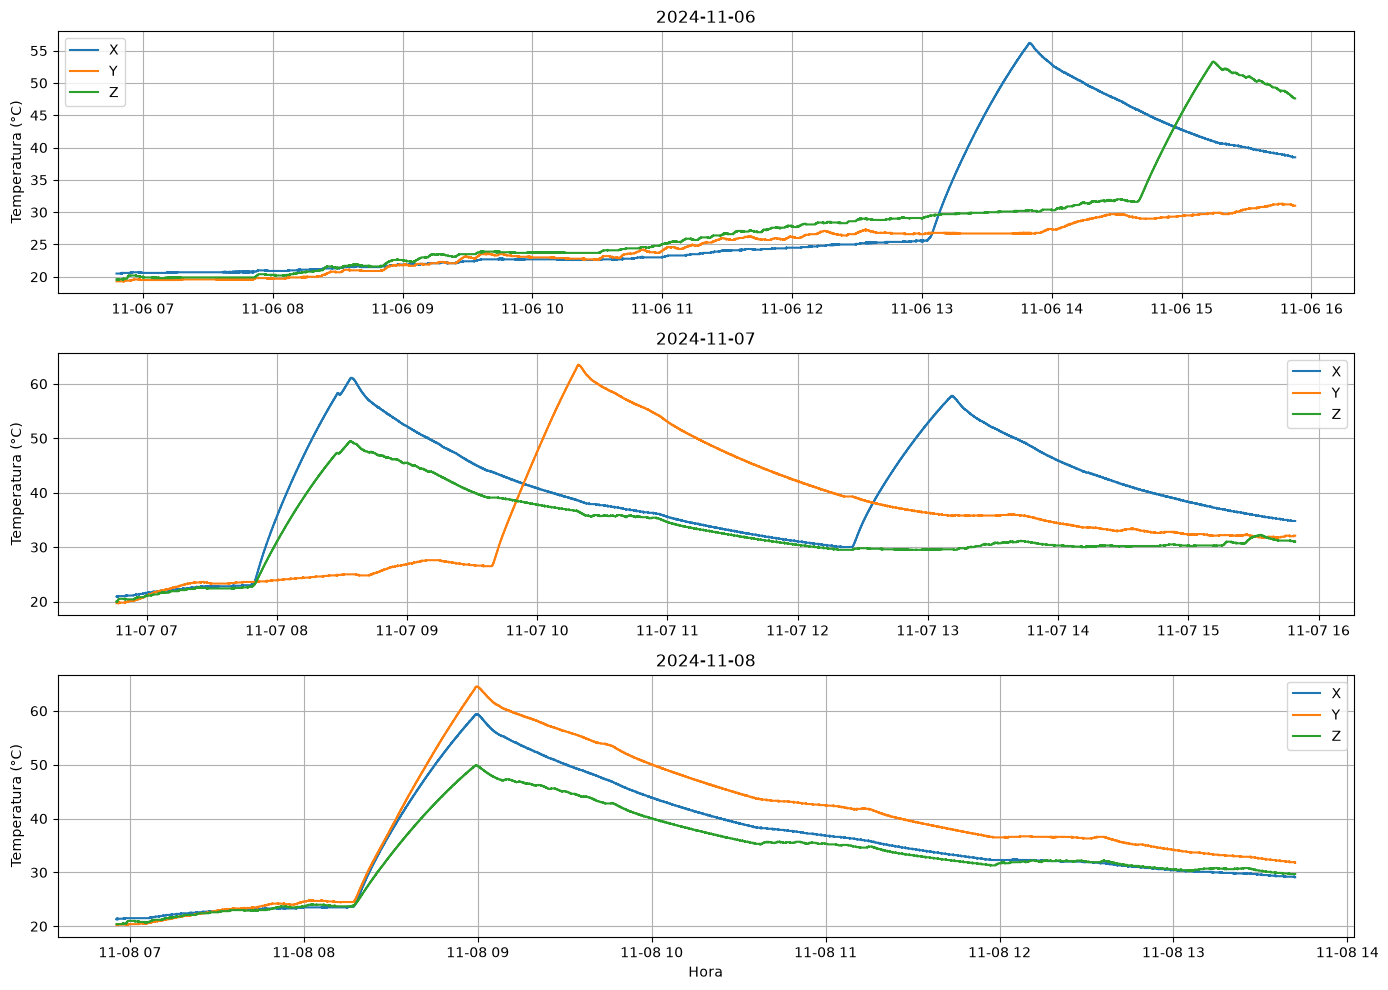

In [148]:
# Evolución temporal de las temperaturas de los ejes

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)

for ax, day in zip(axes, sorted(cnc["Day"].unique())):

    datos_dia = cnc[cnc["Day"] == day]

    ax.plot(datos_dia["Date"], datos_dia["XAxisTemperature"], label="X")
    ax.plot(datos_dia["Date"], datos_dia["YAxisTemperature"], label="Y")
    ax.plot(datos_dia["Date"], datos_dia["ZAxisTemperature"], label="Z")

    ax.set_title(str(day))
    ax.set_ylabel("Temperatura (°C)")
    ax.legend()
    ax.grid(True)

plt.xlabel("Hora")
plt.tight_layout()
plt.show()

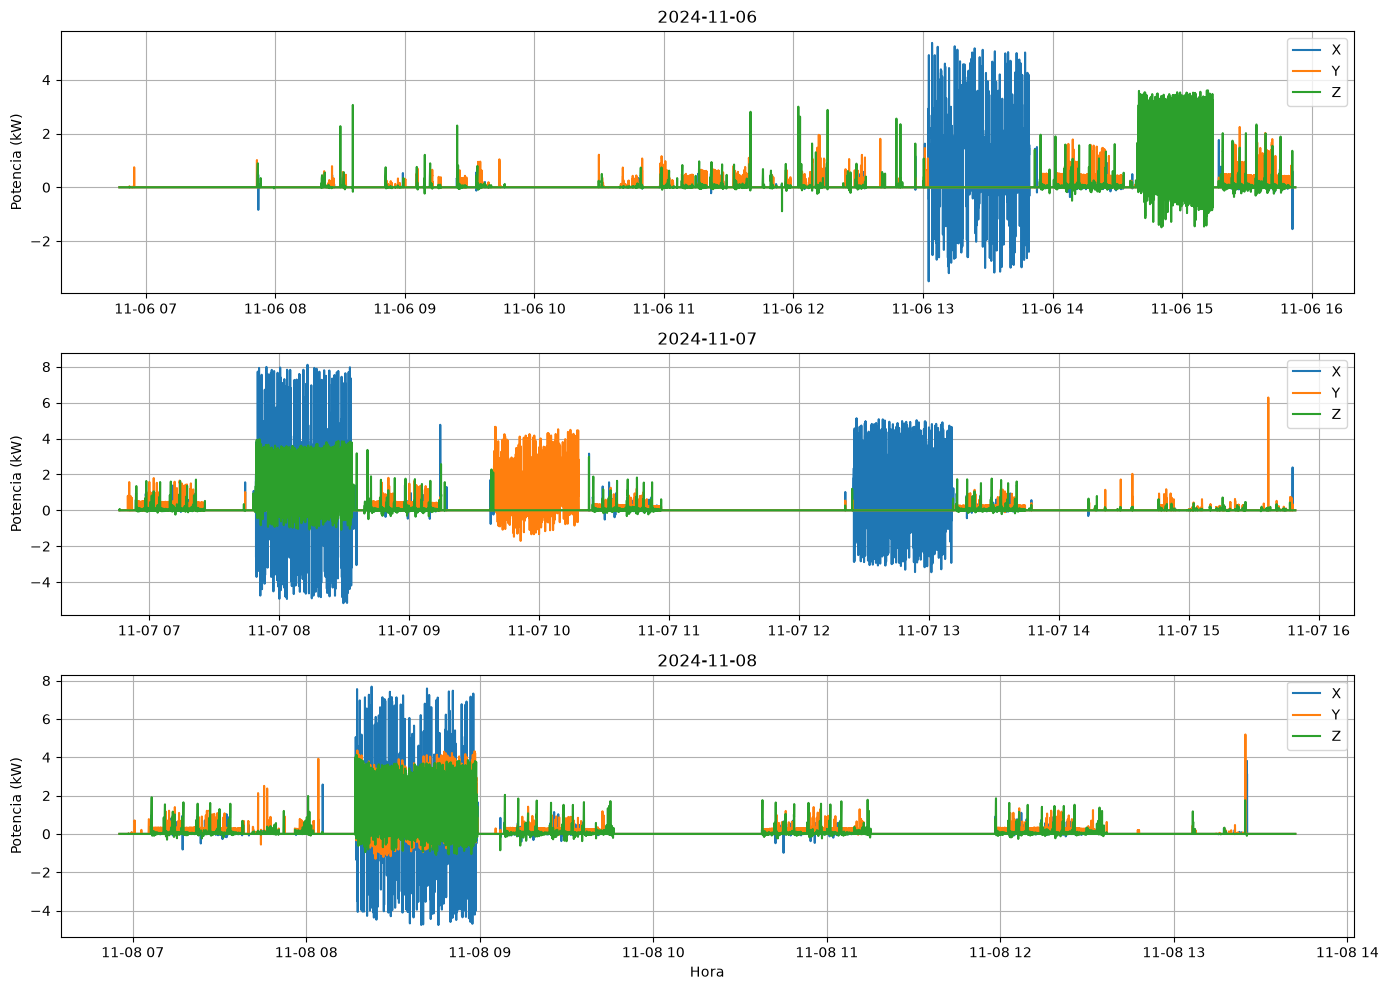

In [149]:
# Evolución de la potencia de los ejes durante cada jornada

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

for ax, day in zip(axes, sorted(cnc["Day"].unique())):

    datos_dia = cnc[cnc["Day"] == day]

    ax.plot(datos_dia["Date"], datos_dia["XAxisPower"], label="X")
    ax.plot(datos_dia["Date"], datos_dia["YAxisPower"], label="Y")
    ax.plot(datos_dia["Date"], datos_dia["ZAxisPower"], label="Z")

    ax.set_title(str(day))
    ax.set_ylabel("Potencia (kW)")
    ax.legend()
    ax.grid(True)

plt.xlabel("Hora")
plt.tight_layout()
plt.show()

In [150]:
# Resumen estadístico de la potencia de los ejes

columnas_potencia = [
    "XAxisPower",
    "YAxisPower",
    "ZAxisPower"
]

print(cnc[columnas_potencia].describe().round(3))

       XAxisPower  YAxisPower  ZAxisPower
count   89655.000   89655.000   89655.000
mean        0.198       0.142       0.125
std         0.744       0.524       0.506
min        -5.178      -1.708      -1.490
25%        -0.000      -0.000      -0.000
50%         0.000       0.000       0.000
75%         0.001       0.000       0.000
max         8.111       6.286       4.125


In [151]:
# Porcentaje de registros con potencia positiva, negativa o cero

for col in columnas_potencia:

    print(f"\n{col}")

    print("Positiva:", (cnc[col] > 0).mean() * 100)
    print("Negativa:", (cnc[col] < 0).mean() * 100)
    print("Cero:", (cnc[col] == 0).mean() * 100)


XAxisPower
Positiva: 61.824772739947576
Negativa: 38.175227260052424
Cero: 0.0

YAxisPower
Positiva: 58.931459483575935
Negativa: 41.068540516424065
Cero: 0.0

ZAxisPower
Positiva: 56.9416095030952
Negativa: 43.0583904969048
Cero: 0.0


In [152]:
# Porcentaje de registros con potencia superior a 0.1 kW en valor absoluto

for col in columnas_potencia:

    actividad = cnc[col].abs() > 0.1

    print(f"\n{col}")
    print("Registros con actividad:", actividad.sum())
    print("Porcentaje:", round(actividad.mean() * 100, 2), "%")


XAxisPower
Registros con actividad: 13070
Porcentaje: 14.58 %

YAxisPower
Registros con actividad: 11458
Porcentaje: 12.78 %

ZAxisPower
Registros con actividad: 9489
Porcentaje: 10.58 %


In [153]:
# Comparar temperatura según actividad de potencia de cada eje

for eje in ["X", "Y", "Z"]:

    potencia = f"{eje}AxisPower"
    temperatura = f"{eje}AxisTemperature"

    cnc[f"{eje}_Active"] = cnc[potencia].abs() > 0.1

    comparacion = cnc.groupby(f"{eje}_Active")[temperatura].agg(
        ["count", "mean", "std"]
    )

    print(f"\nEje {eje}")
    print(comparacion.round(3))


Eje X
          count   mean    std
X_Active                     
False     76585 33.425 10.647
True      13070 42.462 10.525

Eje Y
          count   mean    std
Y_Active                     
False     78197 31.692 10.298
True      11458 38.298 12.835

Eje Z
          count   mean   std
Z_Active                    
False     80166 30.541 7.514
True       9489 37.088 8.691


In [154]:
# Comparar temperatura según actividad, separando por día

for eje in ["X", "Y", "Z"]:

    temperatura = f"{eje}AxisTemperature"
    actividad = f"{eje}_Active"

    resultado = cnc.groupby(
        ["Day", actividad]
    )[temperatura].agg(["count", "mean"])

    print(f"\nEje {eje}")
    print(resultado.round(3))


Eje X
                     count   mean
Day        X_Active              
2024-11-06 False     29126 28.014
           True       3553 40.779
2024-11-07 False     26444 38.609
           True       6137 44.203
2024-11-08 False     21015 34.403
           True       3380 41.070

Eje Y
                     count   mean
Day        Y_Active              
2024-11-06 False     30393 24.572
           True       2286 26.651
2024-11-07 False     28100 34.755
           True       4481 40.417
2024-11-08 False     19704 38.309
           True       4691 41.949

Eje Z
                     count   mean
Day        Z_Active              
2024-11-06 False     29728 27.098
           True       2951 38.801
2024-11-07 False     29293 32.368
           True       3288 36.218
2024-11-08 False     21145 32.850
           True       3250 36.411


In [155]:
# Comparar deformación media según actividad de cada eje

for eje in ["X", "Y", "Z"]:

    actividad = f"{eje}_Active"

    resultado = sensores.merge(
        cnc[["Timestamp", actividad]],
        on="Timestamp",
        how="inner"
    ).groupby(actividad)[subset_ids.columns].mean()

    print(f"\nActividad del eje {eje}")
    print(resultado.round(3))


Actividad del eje X
Empty DataFrame
Columns: [Bar_01, Bar_02, Bar_03, Bar_04, Bar_05, Bar_06, Bar_07, Bar_08, Bar_09, Bar_10, Bar_11, Bar_12, Bar_13, Bar_14]
Index: []

Actividad del eje Y
Empty DataFrame
Columns: [Bar_01, Bar_02, Bar_03, Bar_04, Bar_05, Bar_06, Bar_07, Bar_08, Bar_09, Bar_10, Bar_11, Bar_12, Bar_13, Bar_14]
Index: []

Actividad del eje Z
Empty DataFrame
Columns: [Bar_01, Bar_02, Bar_03, Bar_04, Bar_05, Bar_06, Bar_07, Bar_08, Bar_09, Bar_10, Bar_11, Bar_12, Bar_13, Bar_14]
Index: []


/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_2494/2027437784.py:7: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  resultado = sensores.merge(
/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_2494/2027437784.py:7: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  resultado = sensores.merge(
/var/folders/l5/141qpmhn28g59mlhr87drvs00000gn/T/ipykernel_2494/2027437784.py:7: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  resultado = sensores.merge(


In [156]:
# Comprobar la coincidencia temporal entre ambos datasets

print("CNC:")
print("Timestamp mínimo:", cnc["Timestamp"].min())
print("Timestamp máximo:", cnc["Timestamp"].max())

print("\nSensores:")
print("Timestamp mínimo:", sensores["Timestamp"].min())
print("Timestamp máximo:", sensores["Timestamp"].max())

print("\nTipos:")
print("CNC:", cnc["Timestamp"].dtype)
print("Sensores:", sensores["Timestamp"].dtype)

CNC:
Timestamp mínimo: 1730875667.3620002
Timestamp máximo: 1731073318.3880002

Sensores:
Timestamp mínimo: 1730875807
Timestamp máximo: 1731073367

Tipos:
CNC: float64
Sensores: int64


In [157]:
# Comprobar si los timestamps del CNC coinciden con segundos enteros

print(
    "CNC con timestamp entero:",
    (cnc["Timestamp"] == cnc["Timestamp"].round()).sum()
)

print(
    "CNC con timestamp decimal:",
    (cnc["Timestamp"] != cnc["Timestamp"].round()).sum()
)

CNC con timestamp entero: 0
CNC con timestamp decimal: 89655


In [159]:
# Preparar los datasets para la sincronización temporal

cnc_sync = cnc[
    ["Timestamp", "X_Active", "Y_Active", "Z_Active"]
].copy()

sensores_sync = sensores[
    ["Timestamp"] + list(subset_ids.columns)
].copy()

# Unificar el tipo de dato de los timestamps
sensores_sync["Timestamp"] = sensores_sync["Timestamp"].astype("float64")

# Ordenar cronológicamente
cnc_sync = cnc_sync.sort_values("Timestamp")
sensores_sync = sensores_sync.sort_values("Timestamp")

# Sincronizar por proximidad temporal
datos_sincronizados = pd.merge_asof(
    sensores_sync,
    cnc_sync,
    on="Timestamp",
    direction="nearest",
    tolerance=0.5
)

# Comprobar el resultado
print("Registros de sensores:", len(sensores_sync))
print("Registros sincronizados:", datos_sincronizados["X_Active"].notna().sum())
print("Registros sin sincronizar:", datos_sincronizados["X_Active"].isna().sum())

Registros de sensores: 89393
Registros sincronizados: 89213
Registros sin sincronizar: 180


In [160]:
# Comprobar registros duplicados y sincronización

print("Timestamps duplicados en sensores:")
print(sensores_sync["Timestamp"].duplicated().sum())

print("\nRegistros sincronizados por eje:")

for eje in ["X", "Y", "Z"]:
    columna = f"{eje}_Active"

    print(
        eje,
        datos_sincronizados[columna].notna().sum()
    )

print("\nFechas de los registros sin sincronizar:")

sin_sincronizar = datos_sincronizados[
    datos_sincronizados["X_Active"].isna()
]

print(sin_sincronizar["Timestamp"].head(10))

Timestamps duplicados en sensores:
4

Registros sincronizados por eje:
X 89213
Y 89213
Z 89213

Fechas de los registros sin sincronizar:
32538   1730908348.000
32539   1730908349.000
32540   1730908350.000
32541   1730908351.000
32542   1730908352.000
32543   1730908353.000
32544   1730908354.000
32545   1730908355.000
32546   1730908356.000
32547   1730908357.000
Name: Timestamp, dtype: float64


In [161]:
# Identificar los bloques consecutivos sin sincronización

timestamps_sin_sync = (
    sin_sincronizar["Timestamp"]
    .sort_values()
    .reset_index(drop=True)
)

diferencias = timestamps_sin_sync.diff()

inicios_bloques = timestamps_sin_sync[
    (diferencias != 1) | (diferencias.isna())
]

print("Inicio de cada bloque sin sincronizar:")
print(inicios_bloques)

Inicio de cada bloque sin sincronizar:
0     1730908348.000
68    1730981361.000
69    1730994554.000
128   1731055561.000
129   1731055921.000
130   1731056060.000
131   1731073319.000
Name: Timestamp, dtype: float64


In [162]:
# Mostrar duración y final de cada bloque

bloques = (
    sin_sincronizar
    .sort_values("Timestamp")
    .copy()
)

bloques["Bloque"] = (
    bloques["Timestamp"].diff().ne(1)
).cumsum()

resumen_bloques = bloques.groupby("Bloque")["Timestamp"].agg(
    Inicio="min",
    Final="max",
    Registros="count"
)

print(resumen_bloques)

               Inicio          Final  Registros
Bloque                                         
1      1730908348.000 1730908415.000         68
2      1730981361.000 1730981361.000          1
3      1730994554.000 1730994612.000         59
4      1731055561.000 1731055561.000          1
5      1731055921.000 1731055921.000          1
6      1731056060.000 1731056060.000          1
7      1731073319.000 1731073367.000         49


In [163]:
# Comprobar si un registro CNC se ha asignado a varios registros IDS

coincidencias = datos_sincronizados[
    datos_sincronizados["X_Active"].notna()
]

print(
    "Registros CNC emparejados más de una vez:",
    coincidencias["Timestamp"].value_counts().gt(1).sum()
)

print(
    "\nMáximo de registros IDS asignados al mismo timestamp CNC:",
    coincidencias["Timestamp"].value_counts().max()
)

Registros CNC emparejados más de una vez: 4

Máximo de registros IDS asignados al mismo timestamp CNC: 2


In [164]:
# Mostrar los timestamps CNC que se han utilizado más de una vez

repetidos = coincidencias[
    coincidencias["Timestamp"].duplicated(keep=False)
].sort_values("Timestamp")

print(
    repetidos[
        ["Timestamp"] + list(subset_ids.columns)
    ].to_string(index=False)
)

     Timestamp    Bar_01    Bar_02    Bar_03    Bar_04    Bar_05    Bar_06    Bar_07    Bar_08    Bar_09    Bar_10    Bar_11    Bar_12    Bar_13    Bar_14
1731065441.000 58880.320 61128.550 60269.130 58385.270 63115.890 61866.370 58731.630 60664.250 59868.820 61357.170 58123.780 59696.130 60963.040 58594.390
1731065441.000 58880.300 61128.570 60269.110 58385.290 63115.890 61866.340 58731.740 60664.250 59868.820 61357.190 58123.780 59696.090 60963.040 58594.390
1731065450.000 58880.280 61128.620 60269.110 58385.250 63115.910 61866.320 58731.630 60664.250 59868.820 61357.210 58123.850 59696.060 60963.040 58594.450
1731065450.000 58880.300 61128.550 60269.090 58385.250 63115.840 61866.370 58731.650 60664.250 59868.860 61357.190 58123.800 59696.130 60963.040 58594.410
1731065524.000 58880.180 61128.430 60269.060 58385.220 63116.090 61866.250 58731.610 60664.200 59868.840 61357.240 58123.740 59696.090 60963.040 58594.360
1731065524.000 58880.180 61128.410 60269.090 58385.220 63116.050 61866

In [165]:
# Agrupar las mediciones IDS por timestamp y calcular su media

sensores_ids = (
    sensores.groupby("Timestamp")[list(subset_ids.columns)]
    .mean()
    .reset_index()
)

print("Registros originales:", len(sensores))
print("Registros después de agrupar:", len(sensores_ids))
print(
    "Timestamps duplicados restantes:",
    sensores_ids["Timestamp"].duplicated().sum()
)

Registros originales: 89393
Registros después de agrupar: 89389
Timestamps duplicados restantes: 0


In [166]:
# Preparar los datos para la sincronización

cnc_sync = cnc[
    ["Timestamp", "X_Active", "Y_Active", "Z_Active"]
].copy()

sensores_sync = sensores_ids.copy()

# Unificar tipos de datos
sensores_sync["Timestamp"] = sensores_sync["Timestamp"].astype("float64")

# Ordenar cronológicamente
cnc_sync = cnc_sync.sort_values("Timestamp")
sensores_sync = sensores_sync.sort_values("Timestamp")

# Sincronizar por proximidad temporal
datos_sincronizados = pd.merge_asof(
    sensores_sync,
    cnc_sync,
    on="Timestamp",
    direction="nearest",
    tolerance=0.5
)

# Comprobar sincronización
print("Registros IDS:", len(sensores_sync))
print(
    "Registros sincronizados:",
    datos_sincronizados["X_Active"].notna().sum()
)
print(
    "Registros sin sincronizar:",
    datos_sincronizados["X_Active"].isna().sum()
)

Registros IDS: 89389
Registros sincronizados: 89209
Registros sin sincronizar: 180
